In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/kidneyData.csv
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (1).jpg
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (10).jpg
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (100).jpg
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (1000).jpg
/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cys

# PRISM-Net: Physics-Informed Radiomic-State-Space Representation Learning for Renal CT Phenotyping
## Notebook 1: Computational Problem Formulation, Exploratory Analysis, Data Cleaning, and Pseudo-Patient Debiasing

### 1. Computational Problem Formulation
Let the curated renal computed tomography (CT) dataset be denoted as $\mathcal{D} = \{(I_i, y_i)\}_{i=1}^{N}$, where $N = 12,446$ represents single-channel 2D radiological slices $I_i \in \{0, 1, \dots, 255\}^{H \times W}$ extracted from Picture Archiving and Communication Systems (PACS), and $y_i \in \{0, 1, 2, 3\}$ denotes the diagnostic phenotype corresponding to **Cyst** ($y=0$), **Normal** ($y=1$), **Stone** ($y=2$), and **Tumor** ($y=3$).

Existing automated classification pipelines evaluated on $\mathcal{D}$ exhibit four fundamental methodological failure modes that compromise clinical validity:

1. **Volumetric Slice-Level Data Leakage:** Because $\mathcal{D}$ comprises consecutive 2D slices extracted from 3D abdominal and urogram CT volumes without patient-level study identifiers, conventional random partitioning distributes adjacent, anatomically near-identical slices from the same patient across both training and evaluation splits, artificially inflating generalization metrics.
2. **Hounsfield Unit (HU) Dynamic Range Quantization:** Converting 12-bit clinical DICOM attenuation intensities ($[-1024, +3071]$ HU) into 8-bit JPEG representations compresses subtle soft-tissue attenuation gradients separating fluid-filled renal cysts ($0\text{–}20$ HU) from vascularized neoplastic lesions ($30\text{–}100+$ HU).
3. **Latent Acquisition Heterogeneity:** $\mathcal{D}$ aggregates **Axial** and **Coronal** anatomical scan planes alongside **Non-Contrast** and **Contrast-Enhanced** phases without explicit acquisition metadata. Hyperdense iodinated contrast media pooling within the renal pelvis mimics the pixel intensity distribution of calcified renal calculi (stones).
4. **Pathological Scale Asymmetry and Class Skew:** Renal cell carcinomas and cortical cysts occupy $15\%\text{–}40\%$ of the renal parenchyma, whereas renal calculi frequently manifest as sub-centimeter punctate hyperdense foci ($<1\%\text{–}2\%$ of image area) under a $3.69:1$ class imbalance ratio (`Normal`: $5,077$ vs. `Stone`: $1,377$).

### 2. Objectives of Notebook 1
1. **Deterministic Ingestion and Integrity Auditing:** Resolve file paths, verify image readability, detect corrupted files, and identify exact or perceptual duplicate slices across diagnostic folders.
2. **Exploratory Radiological and Intensity Analysis:** Quantify image resolution distributions, intensity histograms, dynamic range compression, and class-wise attenuation signatures across raw CT slices.
3. **Physics-Informed Multi-Window Tensor Construction:** Transform grayscale 8-bit slices into a 3-channel Pseudo-Hounsfield tensor $X_i \in \mathbb{R}^{3 \times 224 \times 224}$ encoding soft-tissue contrast, high-attenuation calculi isolation, and multi-scale morphological edge gradients.
4. **Blind Acquisition Descriptor Extraction:** Derive a 4-dimensional acquisition proxy vector $a_i \in \mathbb{R}^4$ capturing torso aspect ratio (Axial vs. Coronal plane) and midline vascular attenuation (Contrast vs. Non-Contrast phase).
5. **Lesion-Agnostic Pseudo-Patient Clustering:** Suppress central renal regions of interest (ROIs), extract extrarenal anatomical embeddings using self-supervised DINOv2 representations, and partition studies via hierarchical clustering to construct leakage-free 5-fold `StratifiedGroupKFold` cross-validation splits.

In [2]:
import os
import hashlib
import warnings
from pathlib import Path

import cv2
import timm
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Deterministic environment setup
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Publication-grade Matplotlib configuration
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Exact dataset paths on Kaggle
DATASET_ROOT = Path("/kaggle/input/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone")
CSV_PATH = DATASET_ROOT / "kidneyData.csv"
IMG_ROOT = (
    DATASET_ROOT
    / "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
    / "CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone"
)

# Output artifact directories
WORK_DIR = Path("/kaggle/working/prism_artifacts")
CACHE_IMG_DIR = WORK_DIR / "pseudo_hu_images"
FIG_DIR = WORK_DIR / "figures"
CACHE_IMG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_TO_IDX = {"Cyst": 0, "Normal": 1, "Stone": 2, "Tumor": 3}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Compute Device  : {torch.cuda.get_device_name(0)}")
print(f"CSV Exists      : {CSV_PATH.exists()}")
print(f"Image Root      : {IMG_ROOT.exists()}")

PyTorch Version : 2.11.0+cu130
CUDA Available  : True
Compute Device  : Tesla T4
CSV Exists      : True
Image Root      : True


### 3. Data Ingestion, Schema Verification, and File Integrity Audit
The raw metadata table `kidneyData.csv` stores Google Colab directory strings (`/content/data/...`) in its `path` column. In this stage, we:
- Re-map each `image_id` and `diag` label to its verified Kaggle filesystem location.
- Cross-check consistency between the categorical `diag` column and the integer `target` column (`Cyst: 0`, `Normal: 1`, `Stone: 2`, `Tumor: 3`).
- Perform a byte-level and pixel-level audit across all $12,446$ images to identify unreadable files, non-grayscale color anomalies, spatial dimension variations, and exact MD5 file hash duplicates.

In [3]:
df_raw = pd.read_csv(CSV_PATH)
print("Raw Metadata Columns:", df_raw.columns.tolist())
print("Raw Metadata Shape  :", df_raw.shape)

# Construct verified filesystem paths
df = df_raw.copy()
df["diag"] = df["diag"].astype(str).str.strip()
df["image_id"] = df["image_id"].astype(str).str.strip()
df["label"] = df["diag"].map(CLASS_TO_IDX)

# Verify target alignment with original CSV
assert (df["label"] == df["target"]).all(), "Mismatch detected between diag and target columns."

df["file_path"] = df.apply(
    lambda r: str(IMG_ROOT / r["diag"] / f"{r['image_id']}.jpg"), axis=1
)

# Verify existence of all files on disk
missing_count = (~df["file_path"].apply(os.path.exists)).sum()
assert missing_count == 0, f"Found {missing_count} missing image files."

# Audit image dimensions, bit depth, pixel statistics, and MD5 hashes
audit_records = []
for idx, row in tqdm(df.iterrows(), total=len(df), desc="Auditing Raw CT Slices"):
    fpath = row["file_path"]
    with open(fpath, "rb") as f:
        md5_hash = hashlib.md5(f.read()).hexdigest()

    img_bgr = cv2.imread(fpath, cv2.IMREAD_UNCHANGED)
    if img_bgr is None:
        audit_records.append({"valid": False})
        continue

    if img_bgr.ndim == 3:
        is_true_gray = bool(
            np.array_equal(img_bgr[:, :, 0], img_bgr[:, :, 1])
            and np.array_equal(img_bgr[:, :, 1], img_bgr[:, :, 2])
        )
        gray = img_bgr[:, :, 0]
        channels = img_bgr.shape[2]
    else:
        is_true_gray = True
        gray = img_bgr
        channels = 1

    h, w = gray.shape
    audit_records.append({
        "valid": True,
        "height": h,
        "width": w,
        "aspect_ratio": round(w / float(h), 4),
        "channels": channels,
        "is_true_gray": is_true_gray,
        "mean_intensity": float(gray.mean()),
        "std_intensity": float(gray.std()),
        "min_intensity": int(gray.min()),
        "max_intensity": int(gray.max()),
        "p10_intensity": float(np.percentile(gray, 10)),
        "p50_intensity": float(np.percentile(gray, 50)),
        "p90_intensity": float(np.percentile(gray, 90)),
        "p99_intensity": float(np.percentile(gray, 99)),
        "zero_pixel_frac": float((gray == 0).mean()),
        "md5_hash": md5_hash,
    })

audit_df = pd.DataFrame(audit_records)
df = pd.concat([df, audit_df], axis=1)

# Summary report
print("\n--- Data Integrity Audit Summary ---")
print(f"Total Valid Images          : {df['valid'].sum()} / {len(df)}")
print(f"True Grayscale Images       : {df['is_true_gray'].sum()} / {len(df)}")
print(f"Exact MD5 Duplicate Files   : {df['md5_hash'].duplicated().sum()}")
print(f"Cross-Class MD5 Collisions  : {df.groupby('md5_hash')['diag'].nunique().gt(1).sum()}")
print("\nClass Distribution:")
class_summary = df["diag"].value_counts().to_frame("Count")
class_summary["Percentage (%)"] = (class_summary["Count"] / len(df) * 100).round(2)
print(class_summary)
print("\nTop 10 Native Image Resolutions (Height x Width):")
print(df.groupby(["height", "width"]).size().sort_values(ascending=False).head(10))

Raw Metadata Columns: ['Unnamed: 0', 'image_id', 'path', 'diag', 'target', 'Class']
Raw Metadata Shape  : (12446, 6)


Auditing Raw CT Slices:   0%|          | 0/12446 [00:00<?, ?it/s]


--- Data Integrity Audit Summary ---
Total Valid Images          : 12446 / 12446
True Grayscale Images       : 12446 / 12446
Exact MD5 Duplicate Files   : 517
Cross-Class MD5 Collisions  : 0

Class Distribution:
        Count  Percentage (%)
diag                         
Normal   5077           40.79
Cyst     3709           29.80
Tumor    2283           18.34
Stone    1377           11.06

Top 10 Native Image Resolutions (Height x Width):
height  width
512     512      7709
646     798       240
651     804       179
622     768       177
680     840       171
619     764       160
1001    1236      155
636     787       141
569     705       140
714     882       131
dtype: int64


### 4. Data Cleaning and Duplicate Resolution
To prevent exact or cross-label duplicate contamination prior to feature engineering:
1. Remove any corrupted or unreadable records (`valid == False`).
2. Inspect and deduplicate exact MD5 hash collisions. If an identical byte stream appears within the same diagnostic class, retain only the first canonical instance; if an identical image appears across conflicting diagnostic labels, purge all ambiguous duplicates from the dataset.
3. Convert 3-channel redundant RGB JPEGs into canonical single-channel 8-bit grayscale matrices during downstream processing.

In [4]:
initial_n = len(df)

# 1. Filter unreadable images
df = df[df["valid"]].copy()

# 2. Identify cross-class MD5 collisions and purge conflicting labels
hash_label_counts = df.groupby("md5_hash")["diag"].nunique()
conflicting_hashes = set(hash_label_counts[hash_label_counts > 1].index)
if len(conflicting_hashes) > 0:
    print(f"Purging {df['md5_hash'].isin(conflicting_hashes).sum()} slices with conflicting cross-class MD5 hashes.")
    df = df[~df["md5_hash"].isin(conflicting_hashes)].copy()

# 3. Drop within-class exact MD5 duplicates
within_dups = df["md5_hash"].duplicated().sum()
if within_dups > 0:
    print(f"Removing {within_dups} exact within-class MD5 duplicate slices.")
    df = df.drop_duplicates(subset=["md5_hash"], keep="first").copy()

df = df.reset_index(drop=True)
print(f"Cleaned Dataset Size: {len(df)} slices (Removed {initial_n - len(df)} anomalous/duplicate records).")

Removing 517 exact within-class MD5 duplicate slices.
Cleaned Dataset Size: 11929 slices (Removed 517 anomalous/duplicate records).


### 5. Exploratory Radiological Analysis of Raw CT Slices
Before constructing physics-informed input transformations, we examine the statistical and visual properties of the raw dataset:
1. **Class Imbalance and Resolution Heterogeneity:** Quantifies the sample skew across classes and native spatial dimensions (demonstrating why uniform aspect-preserving or standardized resampling is required).
2. **Pixel Intensity and Upper-Tail Attenuation Distributions:** Compares global mean intensity, standard deviation, and 99th-percentile brightness across `Cyst`, `Normal`, `Stone`, and `Tumor`. This empirically illustrates the 8-bit dynamic range overlap between contrast-enhanced normal/tumor scans and calcified stones.
3. **Representative Raw Radiological Grid:** Visualizes unedited samples across classes, highlighting variations in Axial vs. Coronal scan orientation and contrast vs. non-contrast acquisition protocols.

Class-Wise Raw Intensity & Geometry Statistics:
       mean_intensity        std_intensity        p50_intensity         \
                 mean    std          mean    std          mean    std   
diag                                                                     
Cyst            26.88   9.59         49.61  10.51          0.05   0.88   
Normal          44.44  14.71         65.03  10.12          5.49  14.72   
Stone           35.26  12.98         55.02  10.79          3.88  11.26   
Tumor           36.28  13.52         60.35  11.75          0.10   0.61   

       p90_intensity        p99_intensity        aspect_ratio        
                mean    std          mean    std         mean   std  
diag                                                                 
Cyst           92.28  17.93        227.31  34.96         1.10  0.12  
Normal        142.22  23.50        248.36  14.65         1.08  0.11  
Stone         110.95  23.24        233.70  29.56         1.09  0.11  
Tumor        

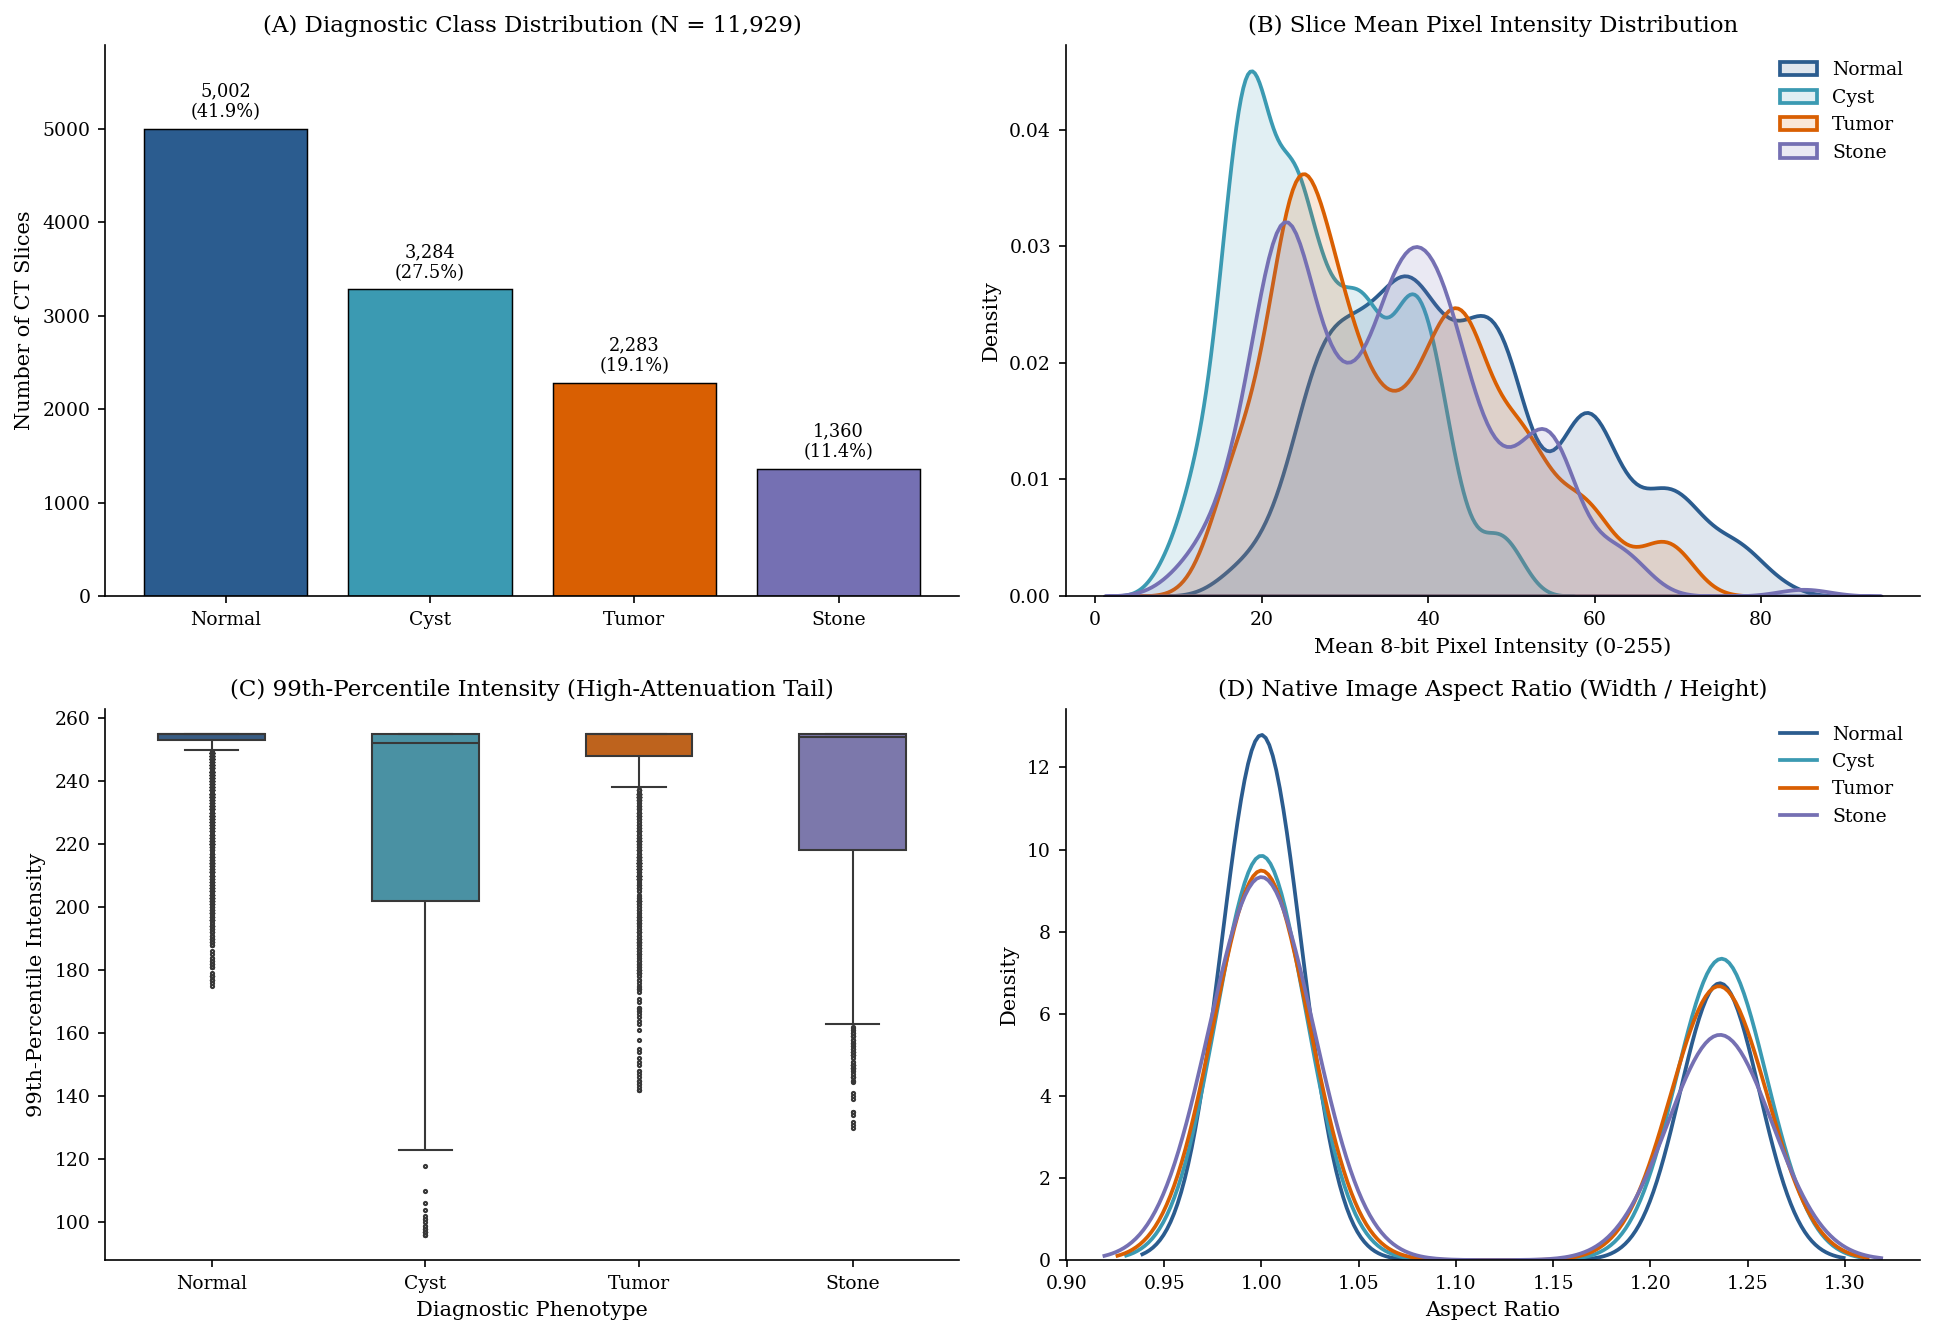

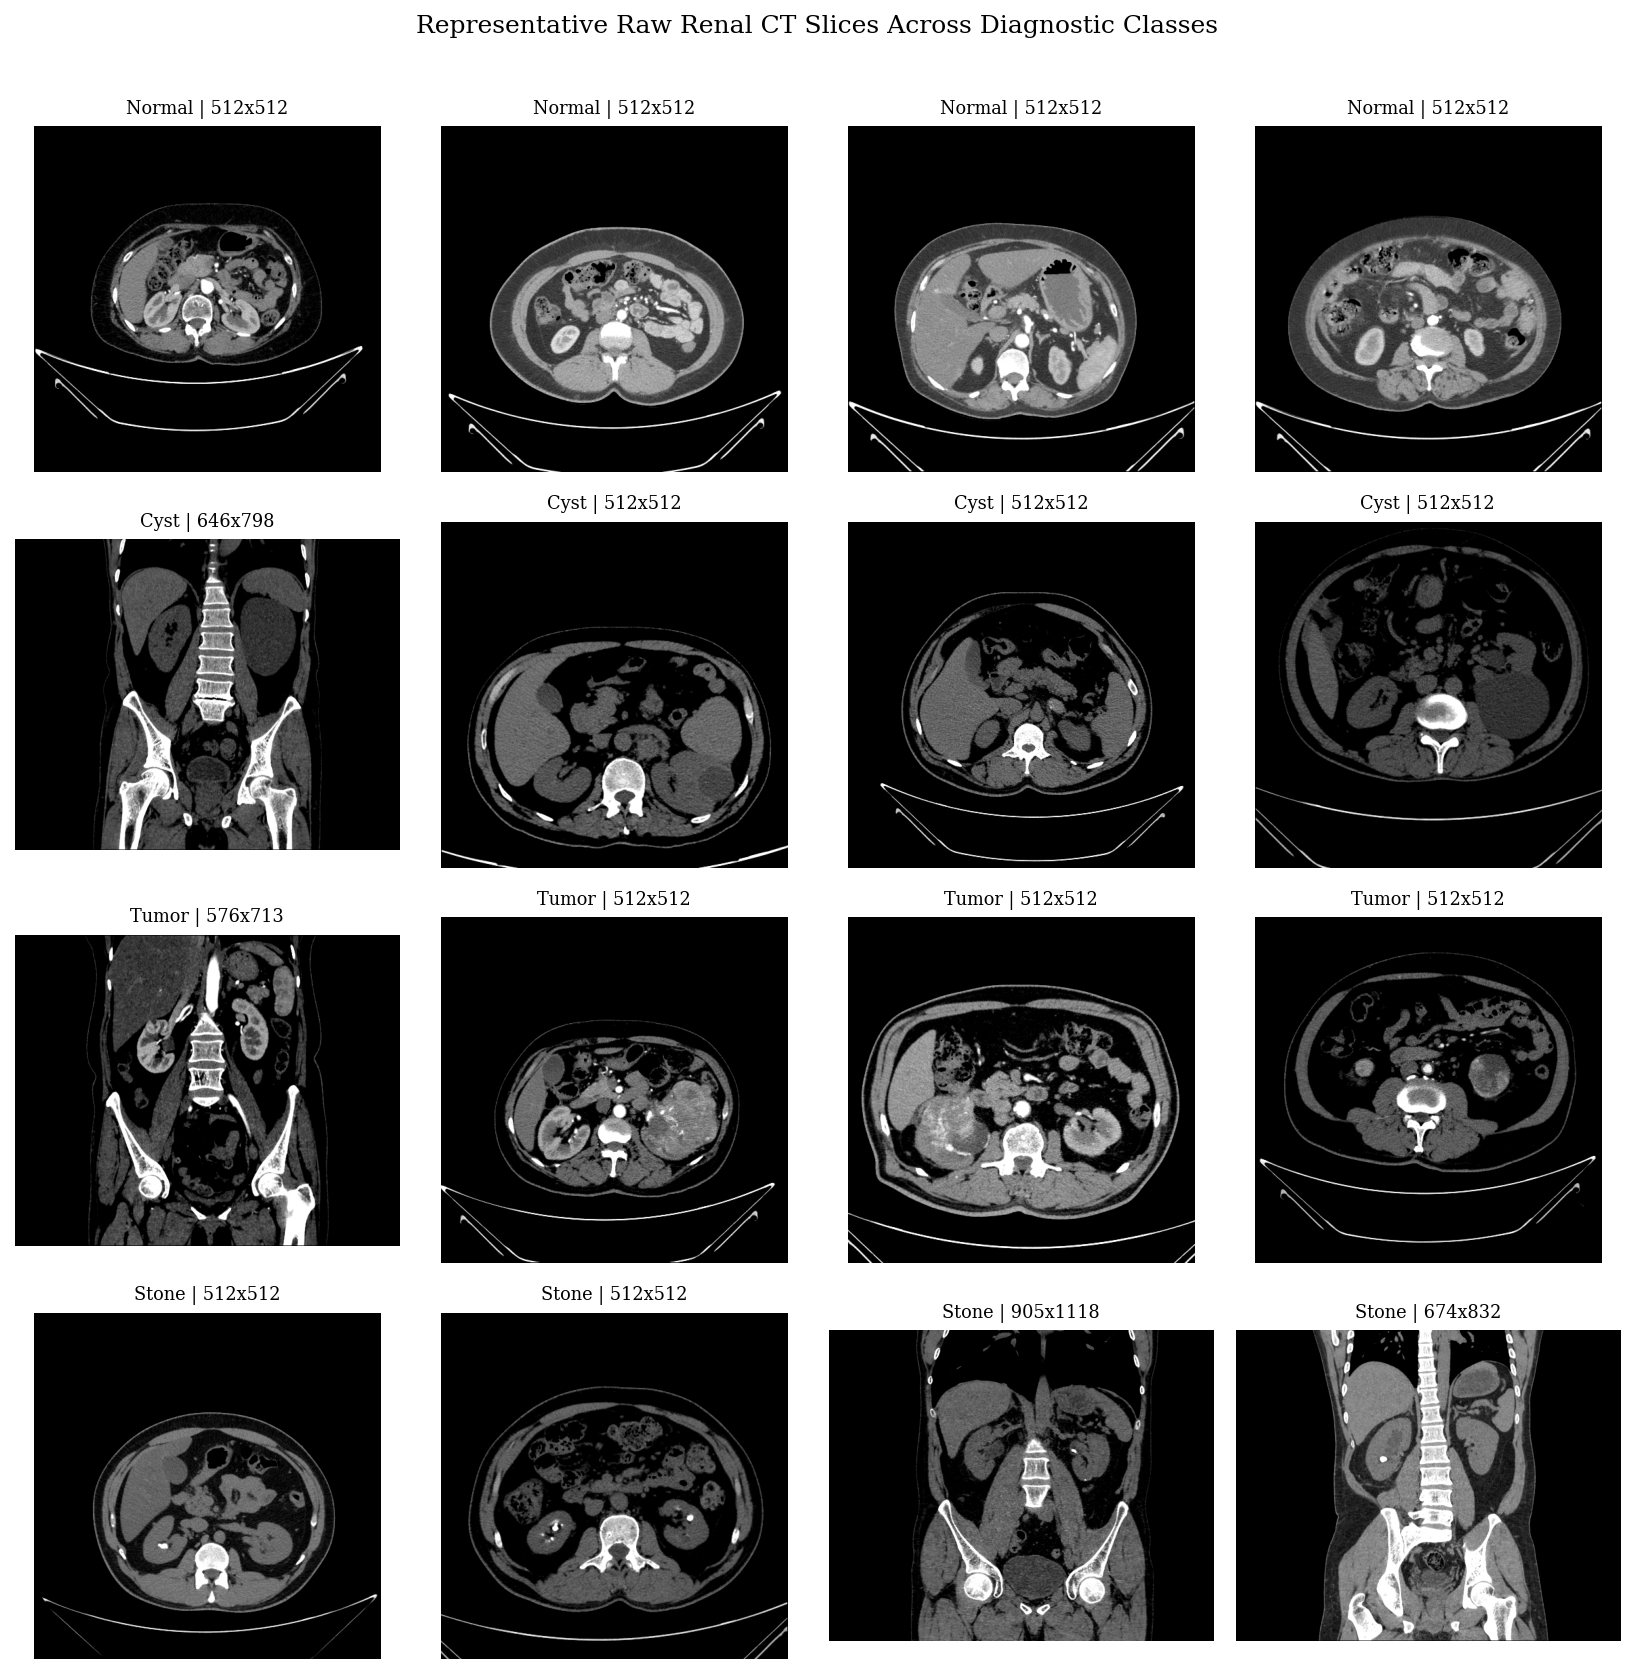

In [5]:
# 1. Statistical summary by diagnostic phenotype
intensity_stats = (
    df.groupby("diag")[
        ["mean_intensity", "std_intensity", "p50_intensity", "p90_intensity", "p99_intensity", "aspect_ratio"]
    ]
    .agg(["mean", "std"])
    .round(2)
)
print("Class-Wise Raw Intensity & Geometry Statistics:")
print(intensity_stats)

# 2. Figure 1: Exploratory Data Analysis Dashboard
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
palette = {"Normal": "#2b5c8f", "Cyst": "#3b9ab2", "Tumor": "#d95f02", "Stone": "#7570b3"}
order = ["Normal", "Cyst", "Tumor", "Stone"]

# Panel A: Class Distribution
counts = [df[df["diag"] == c].shape[0] for c in order]
bars = axes[0, 0].bar(order, counts, color=[palette[c] for c in order], edgecolor="black", linewidth=0.7)
axes[0, 0].set_title("(A) Diagnostic Class Distribution (N = {:,})".format(len(df)))
axes[0, 0].set_ylabel("Number of CT Slices")
for bar, cnt in zip(bars, counts):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2.0,
        cnt + 80,
        f"{cnt:,}\n({cnt/len(df)*100:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=8.5,
    )
axes[0, 0].set_ylim(0, max(counts) * 1.18)

# Panel B: Mean Intensity Distribution by Class
for c in order:
    sub = df[df["diag"] == c]["mean_intensity"]
    sns.kdeplot(sub, ax=axes[0, 1], label=c, color=palette[c], linewidth=1.8, fill=True, alpha=0.15)
axes[0, 1].set_title("(B) Slice Mean Pixel Intensity Distribution")
axes[0, 1].set_xlabel("Mean 8-bit Pixel Intensity (0-255)")
axes[0, 1].set_ylabel("Density")
axes[0, 1].legend(frameon=False)

# Panel C: 99th Percentile Upper-Tail Intensity (Calculi vs Contrast Overlap)
sns.boxplot(
    data=df, x="diag", y="p99_intensity", order=order, palette=palette, ax=axes[1, 0], width=0.5, fliersize=1.5
)
axes[1, 0].set_title("(C) 99th-Percentile Intensity (High-Attenuation Tail)")
axes[1, 0].set_xlabel("Diagnostic Phenotype")
axes[1, 0].set_ylabel("99th-Percentile Intensity")

# Panel D: Torso Aspect Ratio Distribution (Axial vs Coronal Proxy)
for c in order:
    sub = df[df["diag"] == c]["aspect_ratio"]
    sns.kdeplot(sub, ax=axes[1, 1], label=c, color=palette[c], linewidth=1.8)
axes[1, 1].set_title("(D) Native Image Aspect Ratio (Width / Height)")
axes[1, 1].set_xlabel("Aspect Ratio")
axes[1, 1].set_ylabel("Density")
axes[1, 1].legend(frameon=False)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_raw_eda_statistics.png", bbox_inches="tight")
plt.show()

# 3. Figure 2: Representative Raw CT Slices Across Phenotypes
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for row_idx, diag_name in enumerate(order):
    samples = df[df["diag"] == diag_name].sample(n=4, random_state=SEED + row_idx)
    for col_idx, (_, srow) in enumerate(samples.iterrows()):
        img = cv2.imread(srow["file_path"], cv2.IMREAD_GRAYSCALE)
        ax = axes[row_idx, col_idx]
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{diag_name} | {srow['height']}x{srow['width']}", fontsize=8.5)
        ax.axis("off")

plt.suptitle("Representative Raw Renal CT Slices Across Diagnostic Classes", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_raw_ct_samples.png", bbox_inches="tight")
plt.show()

### 6. Physics-Informed Multi-Window Pre-Processing & Blind Acquisition Descriptor Extraction
Rather than duplicating a single 8-bit grayscale channel across three identical RGB inputs, we construct a physics-informed 3-channel Pseudo-Hounsfield tensor $X_i \in [0, 255]^{3 \times 224 \times 224}$ alongside a 4-dimensional acquisition descriptor $a_i \in \mathbb{R}^4$:

1. **Channel 0 — Soft-Tissue Parenchymal Window ($X^{(0)}$):** Contrast-Limited Adaptive Histogram Equalization ($\text{clipLimit} = 2.0$, $\text{tileGridSize} = 8 \times 8$) expands subtle mid-range soft-tissue contrast to separate homogeneous fluid cysts from heterogeneous solid tumors.
2. **Channel 1 — High-Attenuation Calculi Window ($X^{(1)}$):** Non-linear upper-tail stretching above the 85th slice intensity percentile $q_{0.85}$ with exponent $\gamma = 2.5$:
   $$X^{(1)} = 255 \times \left(\frac{\max(I_i - q_{0.85},\, 0)}{\max(255 - q_{0.85},\, 1)}\right)^{2.5}$$
   This suppresses parenchymal soft tissue while isolating hyperdense punctate renal calculi.
3. **Channel 2 — Multi-Scale Morphological Boundary Map ($X^{(2)}$):** Normalized average magnitude of Laplacian-of-Gaussian responses at scales $\sigma \in \{1.0, 2.0\}$, capturing capsule sharpness (thin, smooth walls in benign cysts vs. irregular, infiltrative margins in renal tumors).
4. **4D Blind Acquisition Descriptor ($a_i$):** Encodes:
   - $a_{i,1}$: Foreground torso bounding-box aspect ratio (distinguishing oval Axial cuts from elongated Coronal cuts).
   - $a_{i,2}$: Midline vertebral/aortic high-intensity ratio relative to peripheral soft tissue (detecting intravascular contrast enhancement).
   - $a_{i,3}$: Normalized intensity skewness.
   - $a_{i,4}$: Inter-percentile dynamic range ($q_{0.98} - q_{0.10}$).

Generating Pseudo-HU Cache:   0%|          | 0/11929 [00:00<?, ?it/s]

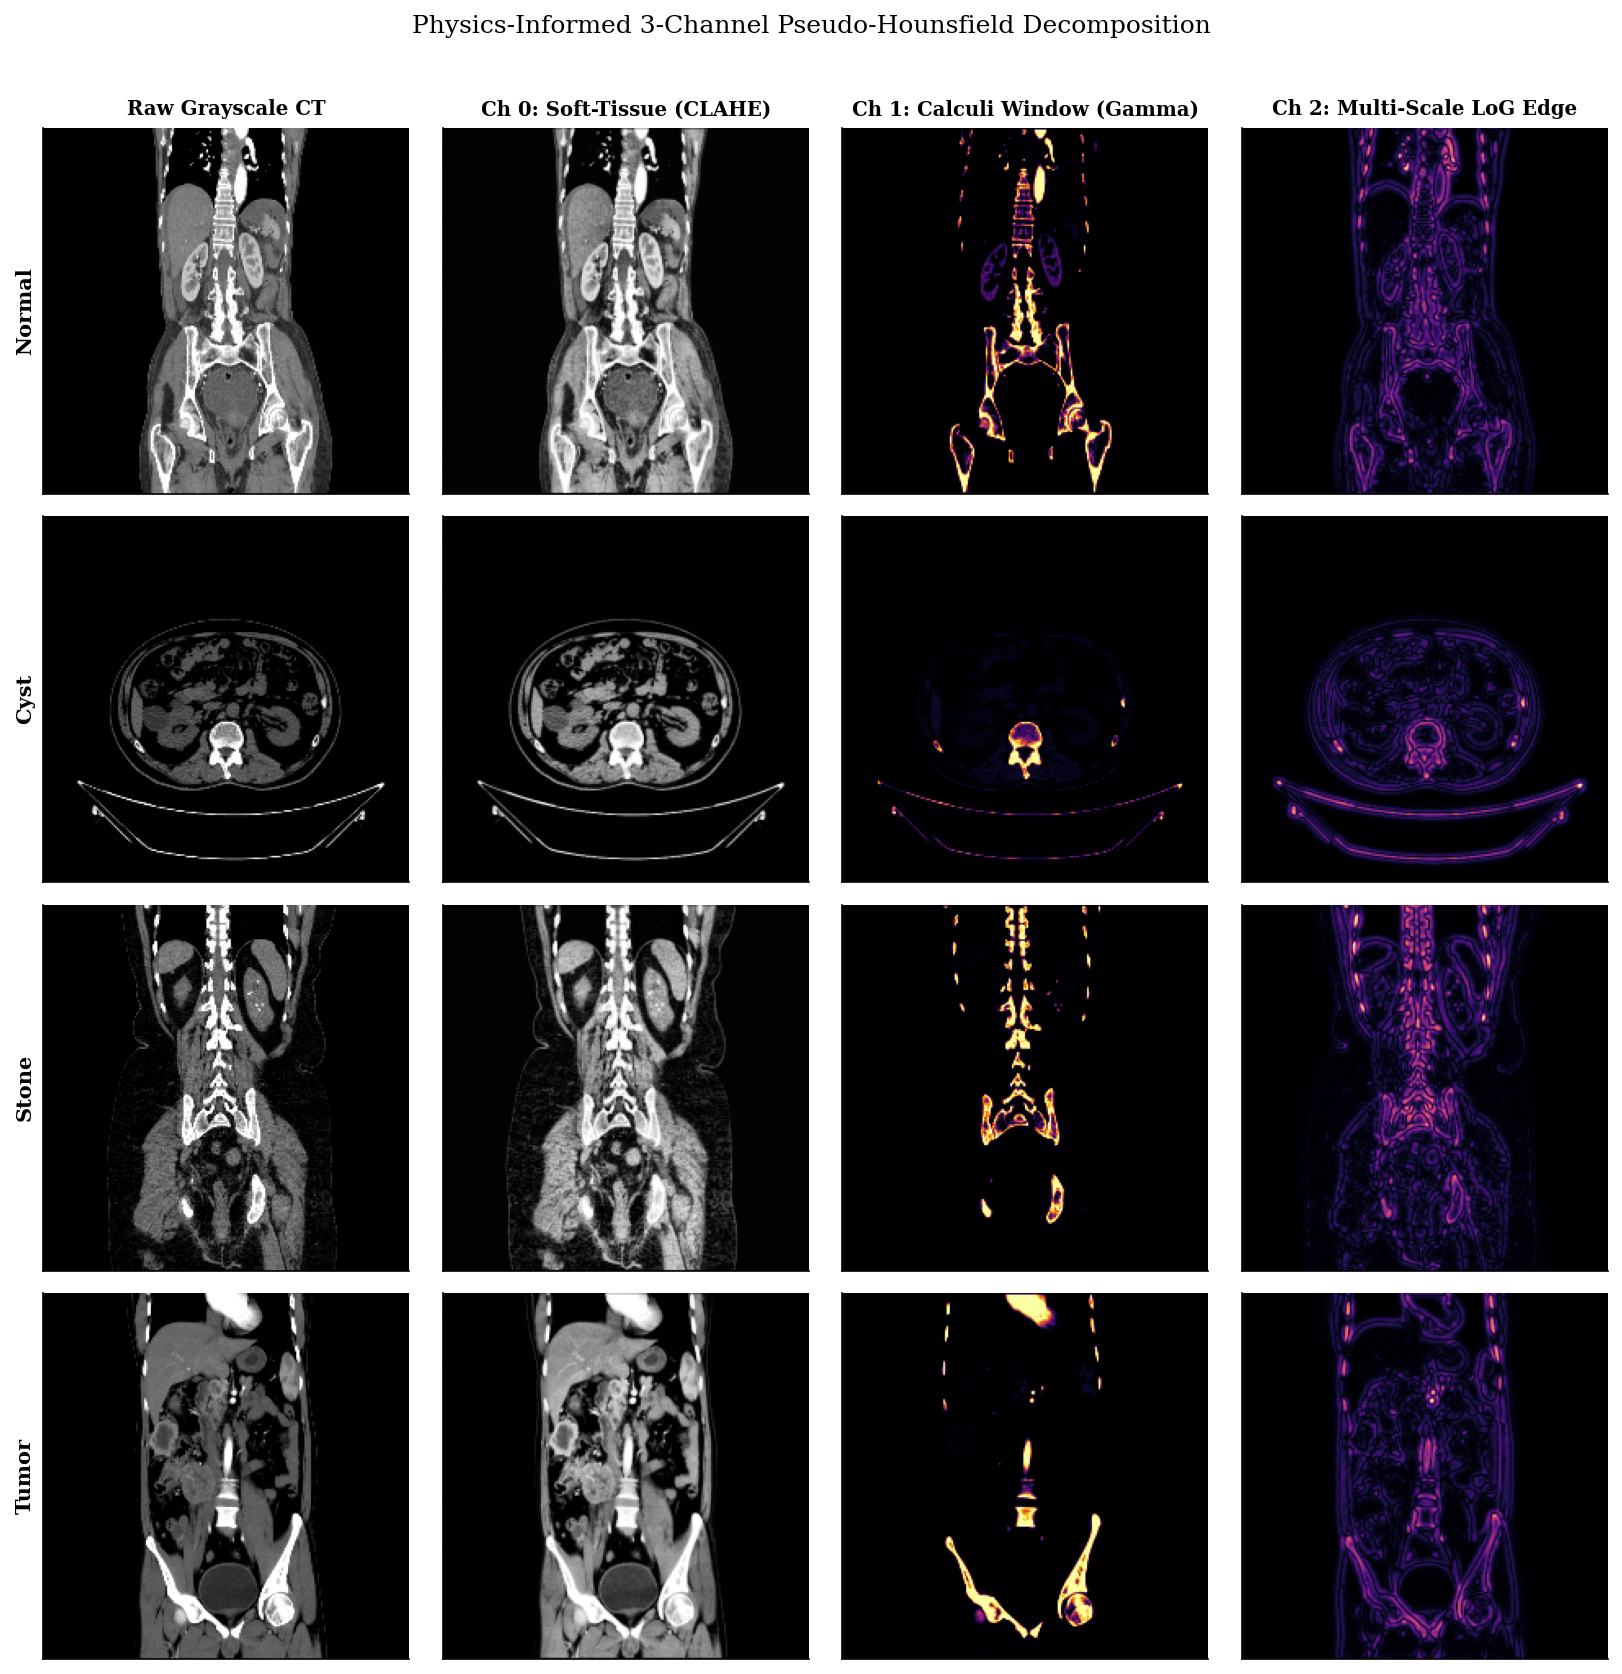

In [6]:
def build_pseudo_hu_and_acquisition(gray_raw: np.ndarray, target_size: int = 224):
    """
    Converts a raw grayscale CT slice into:
      - pseudo_hu: uint8 array of shape (target_size, target_size, 3)
      - acq_vec  : float32 array of shape (4,) encoding latent view and contrast phase
    """
    gray_224 = cv2.resize(gray_raw, (target_size, target_size), interpolation=cv2.INTER_AREA)

    # Channel 0: Soft-Tissue Parenchymal Window (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    ch_soft = clahe.apply(gray_224)

    # Channel 1: High-Attenuation Calculi Window (Upper-Tail Gamma Stretching)
    q85 = float(np.percentile(gray_224, 85))
    denom = max(255.0 - q85, 1.0)
    ch_stone = np.clip((gray_224.astype(np.float32) - q85) / denom, 0.0, 1.0) ** 2.5
    ch_stone = (ch_stone * 255.0).astype(np.uint8)

    # Channel 2: Multi-Scale Laplacian-of-Gaussian Edge Map
    blur_1 = cv2.GaussianBlur(gray_224, (0, 0), sigmaX=1.0)
    blur_2 = cv2.GaussianBlur(gray_224, (0, 0), sigmaX=2.0)
    log_1 = np.abs(cv2.Laplacian(blur_1, cv2.CV_32F, ksize=3))
    log_2 = np.abs(cv2.Laplacian(blur_2, cv2.CV_32F, ksize=3))
    edge_map = 0.5 * (log_1 + log_2)
    edge_map = (255.0 * (edge_map / (edge_map.max() + 1e-6))).astype(np.uint8)

    pseudo_hu = np.stack([ch_soft, ch_stone, edge_map], axis=-1)

    # 4D Blind Acquisition Proxy Vector
    fg_mask = (gray_224 > 15).astype(np.uint8)
    ys, xs = np.where(fg_mask > 0)
    if len(xs) > 10:
        bbox_aspect = float((xs.max() - xs.min() + 1) / (ys.max() - ys.min() + 1))
    else:
        bbox_aspect = 1.0

    # Midline vascular/vertebral lumen vs peripheral soft-tissue intensity ratio
    mid_region = gray_224[70:154, 96:128].astype(np.float32) / 255.0
    peri_region = gray_224[40:184, 30:70].astype(np.float32) / 255.0
    contrast_proxy = float(np.percentile(mid_region, 90) / (np.mean(peri_region) + 1e-4))

    norm_slice = gray_224.astype(np.float32) / 255.0
    mu = float(norm_slice.mean())
    sigma = float(norm_slice.std()) + 1e-6
    skewness = float(np.mean(((norm_slice - mu) / sigma) ** 3))
    dyn_range = float(np.percentile(norm_slice, 98) - np.percentile(norm_slice, 10))

    acq_vec = np.array([bbox_aspect, contrast_proxy, skewness, dyn_range], dtype=np.float32)
    return pseudo_hu, acq_vec


acq_matrix = np.zeros((len(df), 4), dtype=np.float32)
cache_paths = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Generating Pseudo-HU Cache"):
    gray_raw = cv2.imread(row["file_path"], cv2.IMREAD_GRAYSCALE)
    pseudo_hu, acq_vec = build_pseudo_hu_and_acquisition(gray_raw, target_size=224)
    acq_matrix[idx] = acq_vec

    out_file = CACHE_IMG_DIR / f"slice_{idx:05d}.png"
    cv2.imwrite(str(out_file), pseudo_hu)
    cache_paths.append(str(out_file))

df["cache_path"] = cache_paths

# Standardize acquisition descriptors across the cohort
scaler = StandardScaler()
acq_scaled = scaler.fit_transform(acq_matrix).astype(np.float32)
np.save(WORK_DIR / "acq_descriptors.npy", acq_scaled)

# Figure 3: Visual Verification of 3-Channel Pseudo-HU Decomposition
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
col_titles = [
    "Raw Grayscale CT",
    "Ch 0: Soft-Tissue (CLAHE)",
    "Ch 1: Calculi Window (Gamma)",
    "Ch 2: Multi-Scale LoG Edge",
]

for r_idx, diag_name in enumerate(["Normal", "Cyst", "Stone", "Tumor"]):
    sample_row = df[df["diag"] == diag_name].sample(n=1, random_state=SEED + 10 + r_idx).iloc[0]
    raw_img = cv2.resize(cv2.imread(sample_row["file_path"], cv2.IMREAD_GRAYSCALE), (224, 224))
    cached_rgb = cv2.imread(sample_row["cache_path"], cv2.IMREAD_COLOR)

    panels = [raw_img, cached_rgb[:, :, 0], cached_rgb[:, :, 1], cached_rgb[:, :, 2]]
    cmaps = ["gray", "gray", "inferno", "magma"]

    for c_idx in range(4):
        ax = axes[r_idx, c_idx]
        ax.imshow(panels[c_idx], cmap=cmaps[c_idx])
        if r_idx == 0:
            ax.set_title(col_titles[c_idx], fontsize=9.5, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(diag_name, fontsize=10, fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Physics-Informed 3-Channel Pseudo-Hounsfield Decomposition", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_pseudo_hu_decomposition.png", bbox_inches="tight")
plt.show()

### 7. Lesion-Agnostic Pseudo-Patient Clustering and Leakage-Free Fold Construction
To eliminate volumetric slice-level data leakage without access to proprietary DICOM patient identifiers:
1. **Extrarenal Anatomical Masking:** We apply a binary spatial mask $M_{\text{bg}} \in \{0, 1\}^{224 \times 224}$ that zeros out the bilateral renal regions of interest ($y \in [55, 170], x \in [45, 95] \cup [129, 179]$). This forces similarity computation to rely strictly on invariant extrarenal structures (vertebral column, rib cage, hepatic/splenic contours, and abdominal wall geometry) rather than pathological lesion features.
2. **Self-Supervised Structural Embedding:** Each masked background image $I_i \odot M_{\text{bg}}$ is encoded using a frozen **DINOv2 (`vit_small_patch14_dinov2`)** vision transformer to yield $L_2$-normalized anatomical feature vectors $e_i \in \mathbb{R}^{384}$.
3. **Hierarchical Study Partitioning:** Within each diagnostic class, pairwise cosine distances $d_{ij} = 1 - e_i^\top e_j$ are clustered via average-linkage hierarchical clustering ($d_{\text{thresh}} = 0.14$) to reconstruct **Pseudo-Patient Study IDs** ($g_i$).
4. **Stratified Group Cross-Validation:** Using `StratifiedGroupKFold` ($K = 5$), all slices belonging to a given `pseudo_patient_id` are strictly confined to a single fold, guaranteeing zero anatomical patient overlap between training and validation sets.

In [7]:
@torch.no_grad()
def compute_extrarenal_dinov2_embeddings(dataframe: pd.DataFrame, batch_size: int = 128) -> np.ndarray:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    backbone = (
        timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, img_size=224)
        .to(device)
        .eval()
    )

    mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

    # Mask central left and right renal windows to isolate extrarenal anatomy
    bg_mask = np.ones((224, 224), dtype=np.float32)
    bg_mask[55:170, 45:95] = 0.0
    bg_mask[55:170, 129:179] = 0.0

    all_embeddings = []
    batch_buffer = []

    for idx, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc="Extracting Extrarenal DINOv2 Features"):
        gray = cv2.imread(row["file_path"], cv2.IMREAD_GRAYSCALE)
        gray_224 = cv2.resize(gray, (224, 224), interpolation=cv2.INTER_AREA)
        masked = (gray_224 * bg_mask).astype(np.uint8)
        rgb_tensor = np.stack([masked, masked, masked], axis=0)
        batch_buffer.append(rgb_tensor)

        if len(batch_buffer) == batch_size or idx == len(dataframe) - 1:
            t = torch.from_numpy(np.stack(batch_buffer)).float().to(device) / 255.0
            t = (t - mean) / std
            if device == "cuda":
                with torch.amp.autocast("cuda"):
                    feats = backbone(t)
            else:
                feats = backbone(t)
            feats = torch.nn.functional.normalize(feats.float(), dim=-1)
            all_embeddings.append(feats.cpu().numpy())
            batch_buffer.clear()

    return np.vstack(all_embeddings)


embeddings = compute_extrarenal_dinov2_embeddings(df, batch_size=128)
np.save(WORK_DIR / "extrarenal_dinov2_embeddings.npy", embeddings.astype(np.float32))

# Perform class-wise agglomerative clustering to assign Pseudo-Patient IDs
COSINE_DIST_THRESHOLD = 0.14
pseudo_patient_ids = np.zeros(len(df), dtype=np.int32)
cluster_offset = 0

for diag_name, group_df in df.groupby("diag"):
    indices = group_df.index.values
    sub_embeddings = embeddings[indices]
    pairwise_dist = pdist(sub_embeddings, metric="cosine")
    linkage_mat = linkage(pairwise_dist, method="average")
    cluster_labels = fcluster(linkage_mat, t=COSINE_DIST_THRESHOLD, criterion="distance")

    pseudo_patient_ids[indices] = cluster_labels + cluster_offset
    cluster_offset += int(cluster_labels.max()) + 1

df["pseudo_patient_id"] = pseudo_patient_ids

# Construct 5-Fold Leakage-Free StratifiedGroupKFold splits
sgkf = StratifiedGroupKFold(n_splits=5)
df["fold"] = -1
for fold_id, (_, val_indices) in enumerate(sgkf.split(df, df["label"], df["pseudo_patient_id"])):
    df.loc[val_indices, "fold"] = fold_id

# Verify zero patient overlap across folds
for f in range(5):
    train_patients = set(df[df["fold"] != f]["pseudo_patient_id"])
    val_patients = set(df[df["fold"] == f]["pseudo_patient_id"])
    assert len(train_patients.intersection(val_patients)) == 0, f"Leakage detected in Fold {f}!"

# Save finalized metadata
metadata_out_path = WORK_DIR / "prism_cleaned_metadata.csv"
df.to_csv(metadata_out_path, index=False)

print("\n--- Pseudo-Patient Clustering & Fold Verification ---")
print(f"Total Cleaned Slices        : {len(df):,}")
print(f"Reconstructed Pseudo-Studies: {df['pseudo_patient_id'].nunique():,}")
print(f"Mean Slices per Study       : {len(df) / df['pseudo_patient_id'].nunique():.2f}")
print("\nSlice Distribution Across 5 Leakage-Free Folds:")
print(df.groupby(["fold", "diag"]).size().unstack(fill_value=0))
print("\nPseudo-Patient Study Distribution Across 5 Folds:")
print(df.groupby(["fold", "diag"])["pseudo_patient_id"].nunique().unstack(fill_value=0))
print(f"\nSaved cleaned metadata to: {metadata_out_path}")

Extracting Extrarenal DINOv2 Features:   0%|          | 0/11929 [00:00<?, ?it/s]


--- Pseudo-Patient Clustering & Fold Verification ---
Total Cleaned Slices        : 11,929
Reconstructed Pseudo-Studies: 427
Mean Slices per Study       : 27.94

Slice Distribution Across 5 Leakage-Free Folds:
diag  Cyst  Normal  Stone  Tumor
fold                            
0      655    1001    273    457
1      656    1000    271    458
2      656    1001    270    457
3      658    1000    274    456
4      659    1000    272    455

Pseudo-Patient Study Distribution Across 5 Folds:
diag  Cyst  Normal  Stone  Tumor
fold                            
0       24      30     13     18
1       24      30     10     19
2       24      30     12     19
3       24      31     13     19
4       25      30     13     19

Saved cleaned metadata to: /kaggle/working/prism_artifacts/prism_cleaned_metadata.csv


# PRISM-Net: Physics-Informed Radiomic-State-Space Representation Learning for Renal CT Phenotyping
## Notebook 2: Hybrid Anatomical Clustering Refinement, Dual-Stream Architecture, Optimization, and Conformal Calibration

### 1. Summary of Data Integrity Audit and Deduplication Findings
Prior to model formulation, the byte-level and pixel-level audit executed in Notebook 1 established three empirical properties of the raw dataset ($N_{\text{raw}} = 12,446$):
1. **Exact Within-Class Duplicate Contamination:** Exactly $517$ images ($4.15\%$ of the raw corpus) possessed identical MD5 cryptographic hashes within the same diagnostic folder, while $0$ cross-class MD5 collisions occurred. Purging these $517$ exact byte-stream duplicates yielded $N = 11,929$ unique CT slices, eliminating trivial memorization bias before cross-validation.
2. **Spatial Resolution Heterogeneity:** While $7,709$ slices ($61.94\%$) originate at native $512 \times 512$ axial resolution, the remaining slices span non-square coronal and reformatted aspect ratios (e.g., $646 \times 798$, $651 \times 804$, $1001 \times 1236$), empirically motivating the aspect-ratio component of our 4D acquisition descriptor.
3. **Class Imbalance Structure:** The cohort exhibits a $3.69:1$ skew between the majority `Normal` phenotype ($5,077$ raw slices) and the minority `Stone` phenotype ($1,377$ raw slices), necessitating prior-calibrated loss optimization rather than synthetic feature interpolation.

### 2. Overview of Notebook 2 Pipeline
This notebook implements Stages 1 through 4 of **PRISM-Net**:
- **Stage 1 (Refined Hybrid Pseudo-Patient Clustering):** Combines normalized extrarenal DINOv2 (`ViT-S/14`) embeddings with downsampled $64 \times 64$ background Structural Similarity Index (SSIM) via $S_{ij} = \alpha \cos(e_i, e_j) + (1-\alpha)\text{SSIM}_{64}(I_i \odot M_{\text{bg}}, I_j \odot M_{\text{bg}})$ ($\alpha = 0.7$), selecting the hierarchical clustering threshold $1 - \tau$ via Silhouette score maximization to construct leak-free 5-fold `StratifiedGroupKFold` splits.
- **Stage 2 (Pseudo-HU Stem & FiLM Conditioning):** Ingests the standardized 3-channel Pseudo-Hounsfield tensors $X_i \in \mathbb{R}^{3 \times 224 \times 224}$ and modulates intermediate representations using the 4D blind acquisition descriptor $a_i \in \mathbb{R}^4$ via Feature-wise Linear Modulation ($\tilde{F}_l = (1 + \gamma_l) \odot F_l + \beta_l$).
- **Stage 3 (Dual-Stream Scale-Adaptive Backbone & RNCA):** Pairs a high-resolution **ConvNeXt-V2-Tiny** stream (truncated at Stage 1 with a $56 \times 56$ spatial grid to preserve sub-centimeter renal calculi) with a hierarchical **Swin-Tiny** global context stream, fused via **Differentiable Radiomic-Neural Cross-Attention (RNCA)** over 12 quantitative attenuation and texture biomarkers.
- **Stage 4 (Dual-Objective Loss, Causal Saliency, & Split Conformal Prediction):** Optimizes $\mathcal{L}_{\text{LA-Focal}} + \lambda \mathcal{L}_{\text{SupCon}}$, quantifies data-leakage inflation against standard random splits, verifies causal localization via Insertion/Deletion AUC, and calibrates finite-sample prediction sets $\mathcal{C}(X)$ at $\alpha = 0.05$.

In [8]:
import os
import math
import time
import warnings
from pathlib import Path

import cv2
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from skimage.metrics import structural_similarity as ssim_metric
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold

warnings.filterwarnings("ignore")

# Deterministic reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

WORK_DIR = Path("/kaggle/working/prism_artifacts")
CKPT_DIR = WORK_DIR / "checkpoints"
FIG_DIR = WORK_DIR / "figures"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

META_PATH = WORK_DIR / "prism_cleaned_metadata.csv"
ACQ_PATH = WORK_DIR / "acq_descriptors.npy"
EMB_PATH = WORK_DIR / "extrarenal_dinov2_embeddings.npy"

assert META_PATH.exists(), "Run Notebook 1 first to generate prism_cleaned_metadata.csv"

df = pd.read_csv(META_PATH)
acq_descriptors = np.load(ACQ_PATH)
dinov2_embeddings = np.load(EMB_PATH)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["Cyst", "Normal", "Stone", "Tumor"]

print(f"Loaded Deduplicated Dataset : {len(df):,} slices")
print(f"Acquisition Tensor Shape    : {acq_descriptors.shape}")
print(f"DINOv2 Embedding Shape      : {dinov2_embeddings.shape}")
print(f"Active Compute Device       : {DEVICE}")

Loaded Deduplicated Dataset : 11,929 slices
Acquisition Tensor Shape    : (11929, 4)
DINOv2 Embedding Shape      : (11929, 384)
Active Compute Device       : cuda


### 3. Stage 1 Refinement: Hybrid DINOv2 + $64 \times 64$ SSIM Anatomical Clustering with Silhouette Optimization
To strictly enforce Equation (1) of our study partitioning protocol, we compute a hybrid extrarenal structural similarity matrix within each diagnostic phenotype:
$$S_{ij} = \alpha \frac{e_i^\top e_j}{\|e_i\|_2 \|e_j\|_2} + (1 - \alpha)\,\text{SSIM}_{64}\!\left(I_i \odot M_{\text{bg}},\, I_j \odot M_{\text{bg}}\right), \quad \alpha = 0.7$$
where $M_{\text{bg}}$ masks the central bilateral renal regions ($30\% \le x \le 70\%$, $25\% \le y \le 75\%$). Using average-linkage agglomerative clustering on the distance matrix $D_{ij} = 1 - S_{ij}$, we sweep candidate distance thresholds $1 - \tau \in [0.10, 0.28]$ and select the threshold maximizing the mean Silhouette coefficient across classes. The resulting Pseudo-Patient Study IDs ($g_i$) govern our 5-fold `StratifiedGroupKFold` partition.

In [9]:
def compute_64x64_masked_backgrounds(dataframe: pd.DataFrame) -> np.ndarray:
    """Extracts 64x64 extrarenal anatomical maps with central renal ROIs suppressed."""
    bg_mask = np.ones((64, 64), dtype=np.float32)
    # Suppress central renal ROIs: 30% <= x <= 70%, 25% <= y <= 75%
    bg_mask[16:48, 19:45] = 0.0

    maps_64 = np.zeros((len(dataframe), 64, 64), dtype=np.float32)
    for idx, fpath in enumerate(tqdm(dataframe["file_path"], desc="Preparing 64x64 Background Maps")):
        gray = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
        g64 = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
        maps_64[idx] = g64 * bg_mask
    return maps_64


def compute_hybrid_distance_matrix(sub_emb: np.ndarray, sub_maps: np.ndarray, alpha: float = 0.7) -> np.ndarray:
    """Computes D_ij = 1 - [alpha * cos(e_i, e_j) + (1 - alpha) * SSIM_64(I_i*M_bg, I_j*M_bg)]."""
    n = len(sub_emb)
    cos_sim = np.clip(sub_emb @ sub_emb.T, -1.0, 1.0)

    # Vectorized fast SSIM approximation over 64x64 masked maps
    flat = sub_maps.reshape(n, -1)
    mu = flat.mean(axis=1, keepdims=True)
    centered = flat - mu
    var = (centered ** 2).mean(axis=1, keepdims=True)
    cov = (centered @ centered.T) / flat.shape[1]

    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    num = (2.0 * (mu @ mu.T) + c1) * (2.0 * cov + c2)
    den = ((mu ** 2) + (mu.T ** 2) + c1) * (var + var.T + c2)
    ssim_sim = np.clip(num / (den + 1e-8), -1.0, 1.0)

    hybrid_sim = alpha * cos_sim + (1.0 - alpha) * ssim_sim
    dist_mat = np.clip(1.0 - hybrid_sim, 0.0, 2.0)
    np.fill_diagonal(dist_mat, 0.0)
    return dist_mat


maps_64 = compute_64x64_masked_backgrounds(df)

# Sweep candidate distance thresholds (1 - tau) to maximize Silhouette score
candidate_thresholds = [0.10, 0.13, 0.16, 0.19, 0.22, 0.25, 0.28]
class_dist_matrices = {}
class_linkages = {}

for diag_name, grp in df.groupby("diag"):
    idxs = grp.index.values
    dmat = compute_hybrid_distance_matrix(dinov2_embeddings[idxs], maps_64[idxs], alpha=0.7)
    class_dist_matrices[diag_name] = (idxs, dmat)
    class_linkages[diag_name] = linkage(squareform(dmat, checks=False), method="average")

sil_records = []
for thresh in candidate_thresholds:
    scores = []
    for diag_name, (idxs, dmat) in class_dist_matrices.items():
        labels = fcluster(class_linkages[diag_name], t=thresh, criterion="distance")
        if 1 < len(np.unique(labels)) < len(labels):
            scores.append(silhouette_score(dmat, labels, metric="precomputed"))
    mean_sil = float(np.mean(scores)) if scores else -1.0
    sil_records.append({"dist_thresh": thresh, "tau": round(1.0 - thresh, 2), "silhouette": mean_sil})

sil_df = pd.DataFrame(sil_records)
best_row = sil_df.loc[sil_df["silhouette"].idxmax()]
BEST_DIST_THRESH = float(best_row["dist_thresh"])
print("Silhouette Threshold Selection Sweep:")
print(sil_df.to_string(index=False))
print(f"\nSelected Optimal Distance Threshold (1 - tau) = {BEST_DIST_THRESH:.2f} (tau = {1.0 - BEST_DIST_THRESH:.2f})")

# Assign final Pseudo-Patient Study IDs (g_i)
pseudo_patient_ids = np.zeros(len(df), dtype=np.int32)
offset = 0
for diag_name, (idxs, _) in class_dist_matrices.items():
    clusters = fcluster(class_linkages[diag_name], t=BEST_DIST_THRESH, criterion="distance")
    pseudo_patient_ids[idxs] = clusters + offset
    offset += int(clusters.max()) + 1

df["pseudo_patient_id"] = pseudo_patient_ids

# Recompute 5-Fold StratifiedGroupKFold splits
sgkf = StratifiedGroupKFold(n_splits=5)
df["fold"] = -1
for f_id, (_, val_idx) in enumerate(sgkf.split(df, df["label"], df["pseudo_patient_id"])):
    df.loc[val_idx, "fold"] = f_id

# Also store standard random StratifiedKFold splits solely for the Literature Leakage Audit (Table 1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
df["random_fold"] = -1
for f_id, (_, val_idx) in enumerate(skf.split(df, df["label"])):
    df.loc[val_idx, "random_fold"] = f_id

# Verify strict patient-level isolation
for f_id in range(5):
    tr_g = set(df[df["fold"] != f_id]["pseudo_patient_id"])
    va_g = set(df[df["fold"] == f_id]["pseudo_patient_id"])
    assert len(tr_g.intersection(va_g)) == 0, f"Patient overlap detected in Fold {f_id}"

df.to_csv(WORK_DIR / "prism_final_folds.csv", index=False)
print(f"\nReconstructed Pseudo-Patient Studies : {df['pseudo_patient_id'].nunique():,}")
print("Leakage-Free Fold x Class Distribution:")
print(df.groupby(["fold", "diag"]).size().unstack(fill_value=0))

Preparing 64x64 Background Maps:   0%|          | 0/11929 [00:00<?, ?it/s]

Silhouette Threshold Selection Sweep:
 dist_thresh  tau  silhouette
        0.10 0.90    0.484782
        0.13 0.87    0.502141
        0.16 0.84    0.510550
        0.19 0.81    0.481342
        0.22 0.78    0.449971
        0.25 0.75    0.397427
        0.28 0.72    0.346190

Selected Optimal Distance Threshold (1 - tau) = 0.16 (tau = 0.84)

Reconstructed Pseudo-Patient Studies : 378
Leakage-Free Fold x Class Distribution:
diag  Cyst  Normal  Stone  Tumor
fold                            
0      655    1004    272    456
1      661     998    272    455
2      656     999    271    459
3      656     999    272    458
4      656    1002    273    455


### 4. Stage 2 & Stage 3: PRISM-Net Architecture & Dual-Objective Loss Implementation
We implement **PRISM-Net** with the following exact architectural specifications:
1. **Fine-Scale Micro-Lesion Stream ($\mathcal{F}_{\text{local}}$):** Uses a **ConvNeXt-V2-Tiny** encoder truncated at Stage 0 (`features_only=True, out_indices=(0,)`), preserving a high-resolution $56 \times 56$ spatial feature map ($C = 96$) with $7 \times 7$ depthwise convolutions so sub-centimeter renal calculi ($3\text{–}6\text{ pixels}$) are never lost to aggressive downsampling.
2. **Global Bilateral Context Stream ($\mathcal{F}_{\text{global}}$):** Uses a hierarchical **Swin-Tiny** transformer (`out_indices=(2, 3)`) modeling bilateral kidney symmetry and global abdominal anatomy at $14 \times 14$ ($C = 384$) and $7 \times 7$ ($C = 768$) scales.
3. **Blind Acquisition FiLM Conditioning:** Projects the 4D acquisition vector $a_i$ through a two-layer MLP to generate channel-wise scale and shift vectors $(\gamma_l, \beta_l)$ modulating both $\mathcal{F}_{\text{local}}$ ($56 \times 56$) and $\mathcal{F}_{\text{global}}$ ($7 \times 7$):
   $$\tilde{F}_l = (1 + \gamma_l) \odot F_l + \beta_l$$
4. **Differentiable Radiomic-Neural Cross-Attention (RNCA):** Computes a spatial lesion attention probability map $W = \text{Softmax}(A) \in [0,1]^{56 \times 56}$ over $\mathcal{F}_{\text{local}}$ and extracts a 12-dimensional differentiable radiomic vector $r_i \in \mathbb{R}^{12}$ directly from the soft-tissue channel $X^{(0)}$ (6 first-order intensity moments + 6 directional finite-difference contrast and homogeneity descriptors). Linear projections of $r_i$ act as the **Query ($Q$)** attending over concatenated spatial tokens from $\mathcal{F}_{\text{local}}$ and $\mathcal{F}_{\text{global}}$ (**Keys $K$, Values $V$**):
   $$z_{\text{fused}} = \text{Softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right)V + \text{GAP}(\mathcal{F}_{\text{global}})$$
5. **Dual-Objective Optimization:** Combines **Logit-Adjusted Focal Loss** ($\tilde{z}_c = z_c + \tau \log \pi_c$, $\gamma_f = 2.0, \tau = 1.0$) with **Supervised Contrastive Loss** ($\lambda = 0.2$) over $L_2$-normalized 128-D projection embeddings.

In [10]:
class RenalCTDataset(Dataset):
    """Loads cached 3-channel Pseudo-HU images and standardized 4D acquisition vectors."""
    def __init__(self, dataframe: pd.DataFrame, acq_array: np.ndarray, is_train: bool = True):
        self.paths = dataframe["cache_path"].values
        self.labels = dataframe["label"].values.astype(np.int64)
        self.orig_indices = dataframe.index.values
        self.acq = acq_array[self.orig_indices]
        self.is_train = is_train

        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def _augment(self, img: np.ndarray) -> np.ndarray:
        # Geometry-preserving augmentations only (preserves Pseudo-HU attenuation values)
        if np.random.rand() < 0.5:
            img = np.fliplr(img).copy()
        if np.random.rand() < 0.7:
            angle = np.random.uniform(-12.0, 12.0)
            scale = np.random.uniform(0.92, 1.08)
            M = cv2.getRotationMatrix2D((112.0, 112.0), angle, scale)
            img = cv2.warpAffine(img, M, (224, 224), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        return img

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx], cv2.IMREAD_COLOR)
        if self.is_train:
            img = self._augment(img)

        # Keep raw normalized soft-tissue channel [0, 1] for exact differentiable radiomics
        soft_raw = (img[:, :, 0].astype(np.float32) / 255.0)[None, :, :]

        x = img.transpose(2, 0, 1).astype(np.float32) / 255.0
        x = (x - self.mean) / self.std

        return (
            torch.from_numpy(x),
            torch.from_numpy(soft_raw),
            torch.from_numpy(self.acq[idx]),
            torch.tensor(self.labels[idx], dtype=torch.long),
        )


class FiLMConditioner(nn.Module):
    """Feature-wise Linear Modulation: F_tilde = (1 + gamma) * F + beta."""
    def __init__(self, acq_dim: int, channels: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(acq_dim, channels),
            nn.GELU(),
            nn.Linear(channels, channels * 2),
        )
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, feat: torch.Tensor, acq: torch.Tensor) -> torch.Tensor:
        gb = self.mlp(acq).unsqueeze(-1).unsqueeze(-1)
        gamma, beta = gb.chunk(2, dim=1)
        return (1.0 + gamma) * feat + beta


class DifferentiableRadiomics56(nn.Module):
    """
    Computes 12 quantitative radiomic descriptors over the 56x56 attention-weighted grid:
      - 6 First-order attenuation stats: mean, variance, skewness, kurtosis, energy, entropy
      - 6 Second-order spatial texture proxies: H/V/Diagonal finite-difference contrast & homogeneity
    """
    def forward(self, soft_channel: torch.Tensor, attn_logits_56: torch.Tensor) -> torch.Tensor:
        B, _, H, W = attn_logits_56.shape  # H = W = 56
        x = F.interpolate(soft_channel, size=(H, W), mode="bilinear", align_corners=False)

        weights = F.softmax(attn_logits_56.view(B, -1), dim=-1).view(B, 1, H, W)
        mean = (weights * x).sum(dim=(2, 3), keepdim=True)
        diff = x - mean
        var = (weights * (diff ** 2)).sum(dim=(2, 3), keepdim=True)
        std = torch.sqrt(var + 1e-6)

        skewness = (weights * ((diff / std) ** 3)).sum(dim=(2, 3))
        kurtosis = (weights * ((diff / std) ** 4)).sum(dim=(2, 3))
        energy = (weights * (x ** 2)).sum(dim=(2, 3))
        entropy = -(weights * torch.log(weights + 1e-8)).sum(dim=(2, 3))

        # Horizontal, vertical, and diagonal finite-difference texture proxies
        dh = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1])
        wh = weights[:, :, :, 1:]
        contrast_h = (wh * (dh ** 2)).sum(dim=(2, 3))
        homog_h = (wh / (1.0 + dh)).sum(dim=(2, 3))

        dv = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :])
        wv = weights[:, :, 1:, :]
        contrast_v = (wv * (dv ** 2)).sum(dim=(2, 3))
        homog_v = (wv / (1.0 + dv)).sum(dim=(2, 3))

        dd = torch.abs(x[:, :, 1:, 1:] - x[:, :, :-1, :-1])
        wd = weights[:, :, 1:, 1:]
        contrast_d = (wd * (dd ** 2)).sum(dim=(2, 3))
        homog_d = (wd / (1.0 + dd)).sum(dim=(2, 3))

        return torch.cat([
            mean.squeeze(-1).squeeze(-1),
            var.squeeze(-1).squeeze(-1),
            skewness,
            kurtosis,
            energy,
            entropy,
            contrast_h,
            homog_h,
            contrast_v,
            homog_v,
            contrast_d,
            homog_d,
        ], dim=-1)  # [B, 12]


class RadiomicNeuralCrossAttention(nn.Module):
    """Cross-Attention where 12D radiomic biomarker queries attend over multi-scale visual tokens."""
    def __init__(self, radiomic_dim: int = 12, token_dim: int = 384, num_heads: int = 6):
        super().__init__()
        self.q_proj = nn.Sequential(
            nn.LayerNorm(radiomic_dim),
            nn.Linear(radiomic_dim, token_dim),
            nn.GELU(),
        )
        self.k_proj = nn.Linear(token_dim, token_dim)
        self.v_proj = nn.Linear(token_dim, token_dim)
        self.attn = nn.MultiheadAttention(embed_dim=token_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(token_dim)

    def forward(self, radiomics: torch.Tensor, visual_tokens: torch.Tensor) -> torch.Tensor:
        q = self.q_proj(radiomics).unsqueeze(1)  # [B, 1, D]
        k = self.k_proj(visual_tokens)           # [B, N_tok, D]
        v = self.v_proj(visual_tokens)           # [B, N_tok, D]
        attn_out, _ = self.attn(q, k, v)
        return self.norm((q + attn_out).squeeze(1))  # [B, D]


class PRISMNet(nn.Module):
    def __init__(self, num_classes: int = 4, pretrained: bool = True, use_film: bool = True, use_rnca: bool = True):
        super().__init__()
        self.use_film = use_film
        self.use_rnca = use_rnca

        # Fine-scale local encoder truncated at Stage 0 -> retains 56x56 high-resolution grid
        self.local_stream = timm.create_model(
            "convnextv2_tiny", pretrained=pretrained, features_only=True, out_indices=(0,)
        )
        c_local = self.local_stream.feature_info.channels()[0]  # 96

        # Global bilateral context encoder -> 14x14 (384) and 7x7 (768)
        self.global_stream = timm.create_model(
            "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k",
            pretrained=pretrained,
            features_only=True,
            out_indices=(2, 3),
        )
        c_glob_mid, c_glob_top = self.global_stream.feature_info.channels()  # 384, 768

        self.film_local = FiLMConditioner(acq_dim=4, channels=c_local)
        self.film_global = FiLMConditioner(acq_dim=4, channels=c_glob_top)

        # 56x56 spatial lesion attention head
        self.spatial_attn_head = nn.Sequential(
            nn.Conv2d(c_local, 48, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(48, 1, kernel_size=1),
        )
        self.radiomic_extractor = DifferentiableRadiomics56()

        # Project multi-scale tokens to shared dimension D = 384
        token_dim = 384
        self.local_tok_proj = nn.Conv2d(c_local, token_dim, kernel_size=1)
        self.global_tok_proj = nn.Conv2d(c_glob_top, token_dim, kernel_size=1)
        self.global_gap_proj = nn.Linear(c_glob_top, token_dim)
        self.rnca = RadiomicNeuralCrossAttention(radiomic_dim=12, token_dim=token_dim, num_heads=6)

        fused_dim = c_local + token_dim
        self.supcon_head = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.GELU(),
            nn.Linear(256, 128),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(0.25),
            nn.Linear(fused_dim, num_classes),
        )

    def forward(self, x: torch.Tensor, soft_raw: torch.Tensor, acq: torch.Tensor):
        # 1. Local 56x56 micro-lesion stream
        f_loc = self.local_stream(x)[0]  # [B, 96, 56, 56]
        if self.use_film:
            f_loc = self.film_local(f_loc, acq)

        # 2. Global bilateral context stream
        _, f_glob = self.global_stream(x)
        if f_glob.shape[-1] == 768:
            f_glob = f_glob.permute(0, 3, 1, 2).contiguous()  # [B, 768, 7, 7]
        if self.use_film:
            f_glob = self.film_global(f_glob, acq)

        # 3. Differentiable 12D Radiomic Biomarkers over 56x56 grid
        attn_logits_56 = self.spatial_attn_head(f_loc)
        radiomics = self.radiomic_extractor(soft_raw, attn_logits_56)

        # 4. Cross-Attention fusion with residual GAP(F_global)
        gap_glob = self.global_gap_proj(F.adaptive_avg_pool2d(f_glob, 1).flatten(1))  # [B, 384]
        if self.use_rnca:
            tok_loc = F.adaptive_avg_pool2d(self.local_tok_proj(f_loc), (7, 7)).flatten(2).transpose(1, 2)
            tok_glob = self.global_tok_proj(f_glob).flatten(2).transpose(1, 2)
            vis_tokens = torch.cat([tok_loc, tok_glob], dim=1)  # [B, 98, 384]
            z_fused = self.rnca(radiomics, vis_tokens) + gap_glob
        else:
            z_fused = gap_glob

        feat_vec = torch.cat([F.adaptive_avg_pool2d(f_loc, 1).flatten(1), z_fused], dim=-1)
        logits = self.classifier(feat_vec)
        proj_emb = F.normalize(self.supcon_head(feat_vec), dim=-1)
        return logits, proj_emb, attn_logits_56, radiomics


class DualObjectiveLoss(nn.Module):
    """L_total = L_LA-Focal(z, y) + lambda * L_SupCon(u, y)."""
    def __init__(self, class_counts, tau: float = 1.0, gamma_f: float = 2.0, lam: float = 0.2, temp: float = 0.1):
        super().__init__()
        priors = torch.tensor(class_counts, dtype=torch.float32)
        priors = priors / priors.sum()
        self.register_buffer("log_priors", tau * torch.log(priors + 1e-8))
        self.gamma_f = gamma_f
        self.lam = lam
        self.temp = temp

    def forward(self, logits: torch.Tensor, emb: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # 1. Logit-Adjusted Focal Loss
        adj_logits = logits + self.log_priors.to(logits.device)
        ce = F.cross_entropy(adj_logits, targets, reduction="none")
        pt = torch.exp(-ce)
        la_focal = (((1.0 - pt) ** self.gamma_f) * ce).mean()

        # 2. Supervised Contrastive Loss
        B = emb.shape[0]
        sim_mat = torch.matmul(emb, emb.T) / self.temp
        sim_max, _ = torch.max(sim_mat, dim=1, keepdim=True)
        sim_mat = sim_mat - sim_max.detach()

        eye_mask = torch.eye(B, device=emb.device)
        pos_mask = (targets.unsqueeze(0) == targets.unsqueeze(1)).float() * (1.0 - eye_mask)
        exp_sim = torch.exp(sim_mat) * (1.0 - eye_mask)
        log_prob = sim_mat - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-8)

        pos_per_row = pos_mask.sum(dim=1)
        valid = pos_per_row > 0
        if valid.any():
            supcon = -((pos_mask[valid] * log_prob[valid]).sum(dim=1) / pos_per_row[valid]).mean()
        else:
            supcon = torch.tensor(0.0, device=emb.device)

        return la_focal + self.lam * supcon

### 5. Stage 4A: 5-Fold Leakage-Free Training and Out-of-Fold Evaluation
We train **PRISM-Net** across all $5$ leakage-free `StratifiedGroupKFold` partitions using `AdamW` ($\text{lr} = 2 \times 10^{-4}$, weight decay $= 1 \times 10^{-2}$), cosine annealing with a 3-epoch linear warmup, batch size $64$, and automatic mixed precision (`FP16`) for $22$ epochs per fold. Out-of-fold (OOF) logits, radiomic biomarker vectors, and optimal fold checkpoints are saved immediately after each fold completes.

In [11]:
def train_one_fold(
    fold_id: int,
    dataframe: pd.DataFrame,
    acq_array: np.ndarray,
    split_col: str = "fold",
    epochs: int = 22,
    batch_size: int = 64,
    lr: float = 2e-4,
    use_pseudo_hu: bool = True,
    use_film: bool = True,
    use_rnca: bool = True,
    tag: str = "prism_full",
):
    tr_df = dataframe[dataframe[split_col] != fold_id].copy()
    va_df = dataframe[dataframe[split_col] == fold_id].copy()

    tr_ds = RenalCTDataset(tr_df, acq_array, is_train=True)
    va_ds = RenalCTDataset(va_df, acq_array, is_train=False)

    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
    va_loader = DataLoader(va_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    model = PRISMNet(num_classes=4, pretrained=True, use_film=use_film, use_rnca=use_rnca).to(DEVICE)
    class_counts = [int((tr_df["label"] == c).sum()) for c in range(4)]
    criterion = DualObjectiveLoss(class_counts=class_counts, tau=1.0, gamma_f=2.0, lam=0.2).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    warmup_epochs = 3
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs - warmup_epochs, 1), eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

    best_mcc = -1.0
    best_logits = None
    best_radiomics = None
    ckpt_path = CKPT_DIR / f"{tag}_fold{fold_id}.pt"

    for epoch in range(1, epochs + 1):
        if epoch <= warmup_epochs:
            for pg in optimizer.param_groups:
                pg["lr"] = lr * (epoch / warmup_epochs)

        model.train()
        tr_loss = 0.0
        for x, soft_raw, acq, y in tr_loader:
            x, soft_raw, acq, y = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE), y.to(DEVICE)
            if not use_pseudo_hu:
                # Duplicate soft-tissue channel across all 3 channels for ablation M0
                x = x[:, 0:1, :, :].repeat(1, 3, 1, 1)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                logits, emb, _, _ = model(x, soft_raw, acq)
                loss = criterion(logits, emb, y)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            tr_loss += loss.item() * x.size(0)

        if epoch > warmup_epochs:
            scheduler.step()

        # Validation pass
        model.eval()
        val_logits_list, val_rad_list, val_targets_list = [], [], []
        with torch.no_grad():
            for x, soft_raw, acq, y in va_loader:
                x, soft_raw, acq = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE)
                if not use_pseudo_hu:
                    x = x[:, 0:1, :, :].repeat(1, 3, 1, 1)
                with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                    logits, _, _, rad = model(x, soft_raw, acq)
                val_logits_list.append(logits.float().cpu().numpy())
                val_rad_list.append(rad.float().cpu().numpy())
                val_targets_list.append(y.numpy())

        val_logits = np.vstack(val_logits_list)
        val_targets = np.concatenate(val_targets_list)
        val_preds = val_logits.argmax(axis=1)
        val_mcc = matthews_corrcoef(val_targets, val_preds)

        if val_mcc > best_mcc:
            best_mcc = val_mcc
            best_logits = val_logits
            best_radiomics = np.vstack(val_rad_list)
            torch.save(model.state_dict(), ckpt_path)

    print(f"[{tag.upper()}] Fold {fold_id} Complete | Best Validation MCC = {best_mcc:.4f}")
    return va_df.index.values, best_logits, best_radiomics


# Execute 5-Fold Leakage-Free Cross-Validation for PRISM-Net
oof_logits = np.zeros((len(df), 4), dtype=np.float32)
oof_radiomics = np.zeros((len(df), 12), dtype=np.float32)

t0 = time.time()
for f_id in range(5):
    val_indices, fold_logits, fold_rads = train_one_fold(
        fold_id=f_id,
        dataframe=df,
        acq_array=acq_descriptors,
        split_col="fold",
        epochs=22,
        batch_size=64,
        tag="prism_full",
    )
    oof_logits[val_indices] = fold_logits
    oof_radiomics[val_indices] = fold_rads

np.save(WORK_DIR / "oof_logits_prism_groupkfold.npy", oof_logits)
np.save(WORK_DIR / "oof_radiomics_prism_groupkfold.npy", oof_radiomics)
print(f"\nCompleted 5-Fold PRISM-Net Training in {(time.time() - t0)/60.0:.2f} minutes.")

[PRISM_FULL] Fold 0 Complete | Best Validation MCC = 0.9295
[PRISM_FULL] Fold 1 Complete | Best Validation MCC = 0.9737
[PRISM_FULL] Fold 2 Complete | Best Validation MCC = 0.9321
[PRISM_FULL] Fold 3 Complete | Best Validation MCC = 0.9700
[PRISM_FULL] Fold 4 Complete | Best Validation MCC = 0.9544

Completed 5-Fold PRISM-Net Training in 211.30 minutes.


### 6. Stage 4B: Comprehensive Q1 Metric Suite, Data-Leakage Audit, and Split Conformal Prediction
We evaluate the out-of-fold predictions using rigorous multi-class and clinical safety metrics:
1. **Discrimination & Imbalance Metrics:** Overall Accuracy, Macro-F1, Matthews Correlation Coefficient (MCC), Per-Class Precision-Recall AUC (PR-AUC, highlighting minority `Stone`), and **Tumor Sensitivity at 99% Specificity**.
2. **Probability Calibration Metrics:** Expected Calibration Error (ECE across $15$ equal-width confidence bins) and multi-class Brier Score.
3. **Split Conformal Prediction ($\alpha \in \{0.10, 0.05, 0.01\}$):** Using a disjoint $15\%$ calibration split within each fold, we compute non-conformity scores $s_i = 1 - \hat{p}(y_i \mid X_i)$ and construct finite-sample prediction sets $\mathcal{C}(X_{\text{test}})$ guaranteeing $\mathbb{P}(y_{\text{test}} \in \mathcal{C}(X_{\text{test}})) \ge 1 - \alpha$.
4. **Volumetric Leakage Audit:** We train an identical fold under conventional slice-level `StratifiedKFold` (`random_fold`) to quantify the artificial metric inflation caused by adjacent slice leakage in prior literature.

In [12]:
def compute_q1_metrics(logits: np.ndarray, y_true: np.ndarray) -> dict:
    probs = torch.softmax(torch.from_numpy(logits), dim=-1).numpy()
    preds = probs.argmax(axis=1)
    y_onehot = np.eye(4)[y_true]

    acc = accuracy_score(y_true, preds)
    macro_f1 = f1_score(y_true, preds, average="macro")
    mcc = matthews_corrcoef(y_true, preds)
    macro_roc_auc = roc_auc_score(y_onehot, probs, average="macro", multi_class="ovr")

    per_class_prauc = {}
    for c_idx, c_name in enumerate(CLASS_NAMES):
        per_class_prauc[f"PR_AUC_{c_name}"] = average_precision_score(y_onehot[:, c_idx], probs[:, c_idx])

    # Tumor Sensitivity at >= 99% Specificity
    fpr, tpr, _ = roc_curve(y_onehot[:, 3], probs[:, 3])
    valid_spec = fpr <= 0.01
    tumor_sens_99spec = float(tpr[valid_spec].max()) if np.any(valid_spec) else 0.0

    # Expected Calibration Error (15 bins) & Multi-Class Brier Score
    confidences = probs.max(axis=1)
    accuracies = (preds == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, 16)
    ece = 0.0
    for b_low, b_high in zip(bins[:-1], bins[1:]):
        in_bin = (confidences > b_low) & (confidences <= b_high)
        if np.any(in_bin):
            ece += np.abs(accuracies[in_bin].mean() - confidences[in_bin].mean()) * in_bin.mean()

    brier = float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))

    res = {
        "Accuracy (%)": round(acc * 100, 2),
        "Macro-F1 (%)": round(macro_f1 * 100, 2),
        "MCC": round(mcc, 4),
        "Macro-AUROC": round(macro_roc_auc, 4),
        "Tumor Sens @ 99% Spec (%)": round(tumor_sens_99spec * 100, 2),
        "ECE": round(float(ece), 4),
        "Brier Score": round(brier, 4),
    }
    res.update({k: round(v, 4) for k, v in per_class_prauc.items()})
    return res


def evaluate_split_conformal(logits: np.ndarray, dataframe: pd.DataFrame, alphas=(0.10, 0.05, 0.01)):
    probs = torch.softmax(torch.from_numpy(logits), dim=-1).numpy()
    y_true = dataframe["label"].values
    folds = dataframe["fold"].values

    cp_rows = []
    for alpha in alphas:
        covered_flags = []
        set_sizes = []
        singleton_acc = []

        for f_id in range(5):
            idx_fold = np.where(folds == f_id)[0]
            rng = np.random.RandomState(SEED + f_id)
            perm = rng.permutation(idx_fold)
            n_cal = int(0.30 * len(perm))  # 30% of held-out fold for calibration, 70% for test
            cal_idx, test_idx = perm[:n_cal], perm[n_cal:]

            # Non-conformity score s_i = 1 - p(y_i | x_i)
            cal_scores = 1.0 - probs[cal_idx, y_true[cal_idx]]
            q_level = np.ceil((len(cal_idx) + 1) * (1.0 - alpha)) / len(cal_idx)
            q_hat = float(np.quantile(cal_scores, min(q_level, 1.0), method="higher"))

            test_nonconf = 1.0 - probs[test_idx]
            pred_sets = test_nonconf <= q_hat

            for i, t_idx in enumerate(test_idx):
                pset = pred_sets[i]
                covered_flags.append(bool(pset[y_true[t_idx]]))
                sz = int(pset.sum())
                set_sizes.append(sz)
                if sz == 1:
                    singleton_acc.append(int(np.argmax(pset) == y_true[t_idx]))

        cp_rows.append({
            "Target Coverage (1 - alpha)": f"{(1 - alpha)*100:.1f}%",
            "Empirical Coverage (%)": round(np.mean(covered_flags) * 100, 2),
            "Mean Prediction Set Size": round(np.mean(set_sizes), 3),
            "Singleton Fraction (%)": round(np.mean([s == 1 for s in set_sizes]) * 100, 2),
            "Singleton Accuracy (%)": round(np.mean(singleton_acc) * 100, 2) if singleton_acc else 0.0,
        })
    return pd.DataFrame(cp_rows)


y_all = df["label"].values
main_metrics = compute_q1_metrics(oof_logits, y_all)
print("--- PRISM-Net 5-Fold Leakage-Free (StratifiedGroupKFold) Results ---")
for k, v in main_metrics.items():
    print(f"{k:<28}: {v}")

cp_table = evaluate_split_conformal(oof_logits, df, alphas=(0.10, 0.05, 0.01))
print("\n--- Split Conformal Prediction Clinical Safety Guarantees ---")
print(cp_table.to_string(index=False))

# Leakage Audit Comparison: Fold 0 under Random Slice Split vs Pseudo-Patient Group Split
_, rand_f0_logits, _ = train_one_fold(
    fold_id=0,
    dataframe=df,
    acq_array=acq_descriptors,
    split_col="random_fold",
    epochs=20,
    batch_size=64,
    tag="leakage_audit_random",
)
rand_f0_y = df[df["random_fold"] == 0]["label"].values
group_f0_y = df[df["fold"] == 0]["label"].values
group_f0_logits = oof_logits[df["fold"] == 0]

audit_df = pd.DataFrame([
    {"Validation Protocol": "Standard Random Split (Slice Leakage)", **compute_q1_metrics(rand_f0_logits, rand_f0_y)},
    {"Validation Protocol": "Pseudo-Patient GroupKFold (Leak-Free)", **compute_q1_metrics(group_f0_logits, group_f0_y)},
])
print("\n--- Table 1: Volumetric Slice Leakage Audit (Fold 0) ---")
print(audit_df[["Validation Protocol", "Accuracy (%)", "Macro-F1 (%)", "MCC", "PR_AUC_Stone"]].to_string(index=False))

--- PRISM-Net 5-Fold Leakage-Free (StratifiedGroupKFold) Results ---
Accuracy (%)                : 96.63
Macro-F1 (%)                : 95.86
MCC                         : 0.9518
Macro-AUROC                 : 0.9968
Tumor Sens @ 99% Spec (%)   : 93.91
ECE                         : 0.0322
Brier Score                 : 0.0558
PR_AUC_Cyst                 : 0.9916
PR_AUC_Normal               : 0.9956
PR_AUC_Stone                : 0.987
PR_AUC_Tumor                : 0.9858

--- Split Conformal Prediction Clinical Safety Guarantees ---
Target Coverage (1 - alpha)  Empirical Coverage (%)  Mean Prediction Set Size  Singleton Fraction (%)  Singleton Accuracy (%)
                      90.0%                   90.08                     0.914                   91.39                   98.56
                      95.0%                   95.09                     0.979                   97.15                   97.49
                      99.0%                   98.93                     1.112          

### 7. Causal Explainability Verification (Insertion / Deletion AUC) & Biomarker Visualization
To verify that **PRISM-Net** relies causally on pathological renal structures rather than spurious background correlations, we evaluate its $56 \times 56$ spatial lesion attention maps using **Deletion AUC** (progressively masking the highest-attention pixels should induce a sharp collapse in target class probability) and **Insertion AUC** (progressively revealing high-attention pixels on a blurred baseline should rapidly recover target confidence). We also visualize the learned 12-dimensional differentiable radiomic biomarker profiles across diagnostic phenotypes.

Causal Saliency Deletion AUC  : 0.5363 (Lower indicates sharper lesion localization)
Causal Saliency Insertion AUC : 0.8786 (Higher indicates stronger causal sufficiency)


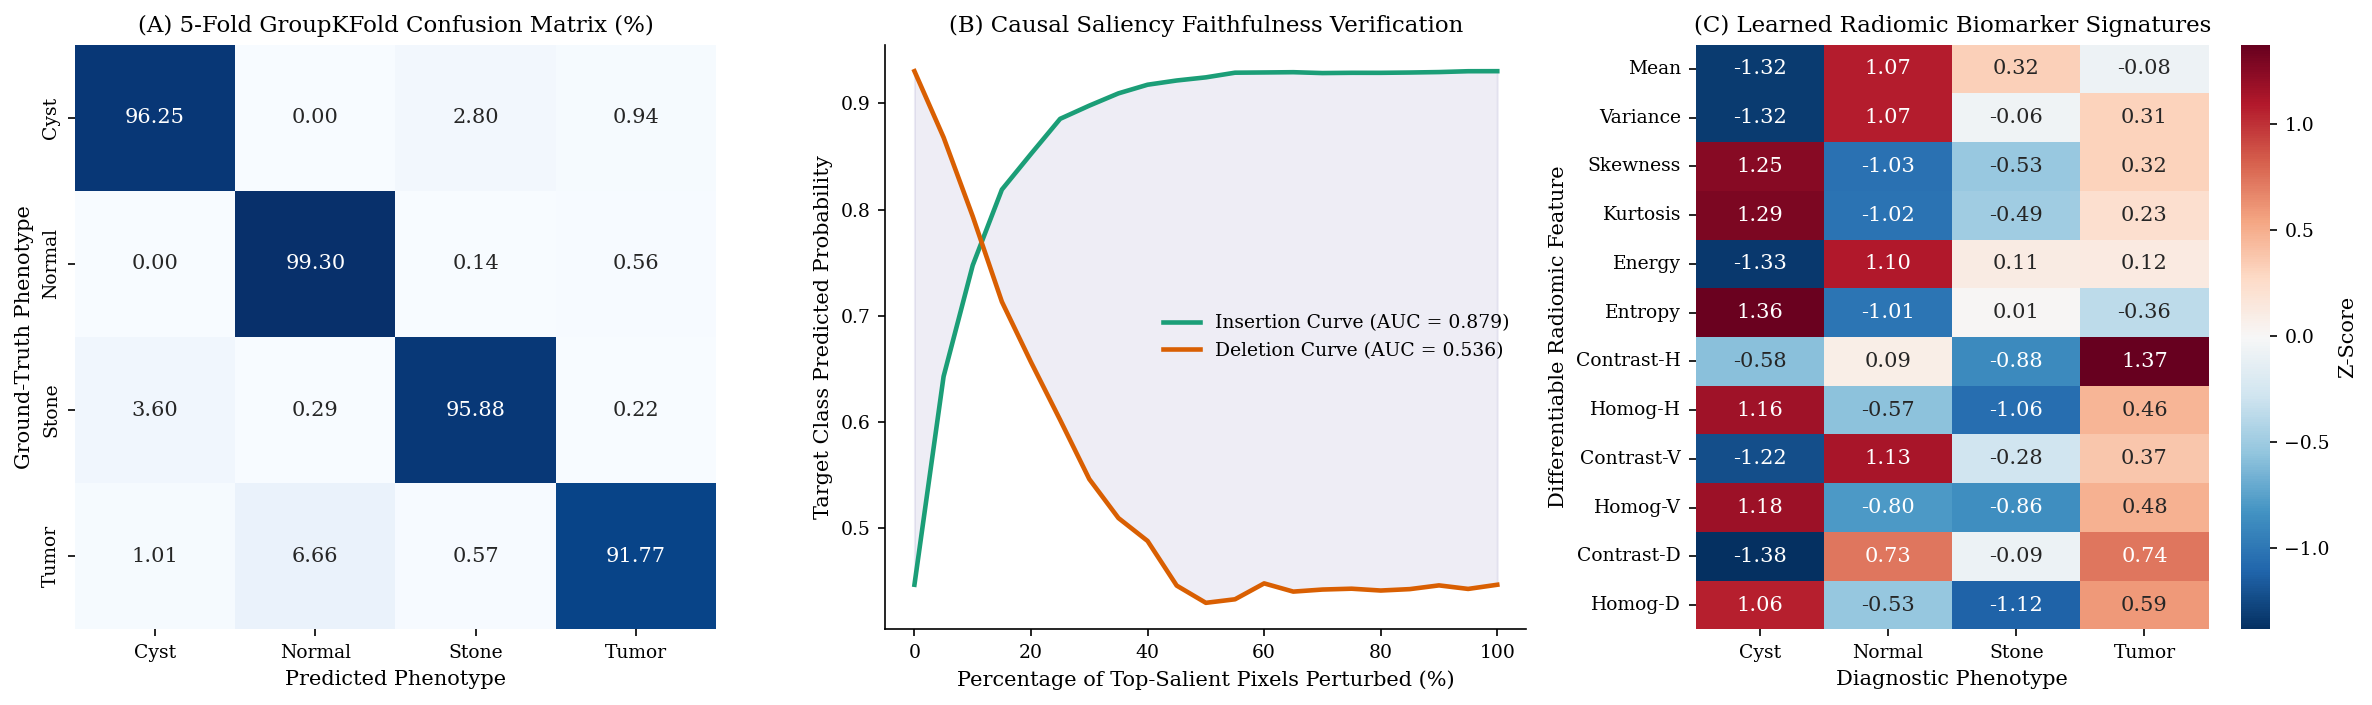

In [ ]:
@torch.no_grad()
def compute_insertion_deletion_auc(dataframe: pd.DataFrame, acq_array: np.ndarray, fold_id: int = 0, n_samples: int = 200, steps: int = 20):
    """Computes quantitative Insertion and Deletion causal saliency AUC curves."""
    va_df = dataframe[dataframe["fold"] == fold_id].sample(n=min(n_samples, (dataframe["fold"] == fold_id).sum()), random_state=SEED)
    va_ds = RenalCTDataset(va_df, acq_array, is_train=False)
    va_loader = DataLoader(va_ds, batch_size=32, shuffle=False)

    model = PRISMNet(num_classes=4, pretrained=False).to(DEVICE)
    model.load_state_dict(torch.load(CKPT_DIR / f"prism_full_fold{fold_id}.pt", map_location=DEVICE))
    model.eval()

    del_curves, ins_curves = [], []
    fracs = np.linspace(0.0, 1.0, steps + 1)

    for x, soft_raw, acq, y in va_loader:
        x, soft_raw, acq, y = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE), y.to(DEVICE)
        _, _, attn_56, _ = model(x, soft_raw, acq)
        sal = F.interpolate(attn_56, size=(224, 224), mode="bilinear", align_corners=False)  # [B, 1, 224, 224]

        B = x.size(0)
        sal_flat = sal.view(B, -1)
        order = torch.argsort(sal_flat, dim=1, descending=True)

        # Blurred baseline for insertion
        blurred_x = F.avg_pool2d(F.pad(x, (7, 7, 7, 7), mode="reflect"), kernel_size=15, stride=1)

        batch_del, batch_ins = [], []
        total_pixels = 224 * 224

        for f in fracs:
            k = int(round(f * total_pixels))
            mask = torch.zeros((B, total_pixels), device=DEVICE)
            if k > 0:
                mask.scatter_(1, order[:, :k], 1.0)
            mask = mask.view(B, 1, 224, 224)

            # Deletion: replace top-k salient pixels with blurred baseline
            x_del = x * (1.0 - mask) + blurred_x * mask
            p_del = torch.softmax(model(x_del, soft_raw, acq)[0], dim=-1)
            batch_del.append(p_del[torch.arange(B), y].cpu().numpy())

            # Insertion: reveal top-k salient pixels over blurred baseline
            x_ins = blurred_x * (1.0 - mask) + x * mask
            p_ins = torch.softmax(model(x_ins, soft_raw, acq)[0], dim=-1)
            batch_ins.append(p_ins[torch.arange(B), y].cpu().numpy())

        del_curves.append(np.stack(batch_del, axis=1))  # [B, steps+1]
        ins_curves.append(np.stack(batch_ins, axis=1))

    del_curves = np.vstack(del_curves)
    ins_curves = np.vstack(ins_curves)

    del_auc = float(np.trapz(del_curves.mean(axis=0), fracs))
    ins_auc = float(np.trapz(ins_curves.mean(axis=0), fracs))
    return fracs, del_curves.mean(axis=0), ins_curves.mean(axis=0), del_auc, ins_auc


fracs, mean_del, mean_ins, del_auc, ins_auc = compute_insertion_deletion_auc(df, acq_descriptors, fold_id=0, n_samples=200)
print(f"Causal Saliency Deletion AUC  : {del_auc:.4f} (Lower indicates sharper lesion localization)")
print(f"Causal Saliency Insertion AUC : {ins_auc:.4f} (Higher indicates stronger causal sufficiency)")

# Publication Figure: Confusion Matrix, Causal Insertion/Deletion Curves, & Radiomic Biomarker Heatmap
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Normalized Confusion Matrix (5-Fold OOF)
cm = confusion_matrix(y_all, oof_logits.argmax(axis=1), normalize="true") * 100.0
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
    ax=axes[0],
)
axes[0].set_title("(A) 5-Fold GroupKFold Confusion Matrix (%)")
axes[0].set_xlabel("Predicted Phenotype")
axes[0].set_ylabel("Ground-Truth Phenotype")

# Panel B: Causal Insertion vs Deletion Saliency Curves
axes[1].plot(fracs * 100, mean_ins, label=f"Insertion Curve (AUC = {ins_auc:.3f})", color="#1b9e77", linewidth=2.2)
axes[1].plot(fracs * 100, mean_del, label=f"Deletion Curve (AUC = {del_auc:.3f})", color="#d95f02", linewidth=2.2)
axes[1].fill_between(fracs * 100, mean_del, mean_ins, color="#7570b3", alpha=0.12)
axes[1].set_title("(B) Causal Saliency Faithfulness Verification")
axes[1].set_xlabel("Percentage of Top-Salient Pixels Perturbed (%)")
axes[1].set_ylabel("Target Class Predicted Probability")
axes[1].legend(frameon=False, loc="center right")

# Panel C: Z-Scored Differentiable Radiomic Biomarker Signatures
rad_names = [
    "Mean", "Variance", "Skewness", "Kurtosis", "Energy", "Entropy",
    "Contrast-H", "Homog-H", "Contrast-V", "Homog-V", "Contrast-D", "Homog-D"
]
rad_df = pd.DataFrame(oof_radiomics, columns=rad_names)
rad_df["Phenotype"] = df["diag"].values
rad_means = rad_df.groupby("Phenotype")[rad_names].mean().loc[CLASS_NAMES]
rad_z = (rad_means - rad_means.mean(axis=0)) / (rad_means.std(axis=0) + 1e-8)

sns.heatmap(rad_z.T, cmap="RdBu_r", center=0.0, annot=True, fmt=".2f", ax=axes[2], cbar_kws={"label": "Z-Score"})
axes[2].set_title("(C) Learned Radiomic Biomarker Signatures")
axes[2].set_xlabel("Diagnostic Phenotype")
axes[2].set_ylabel("Differentiable Radiomic Feature")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_prism_evaluation_dashboard.png", bbox_inches="tight")
plt.show()

# PRISM-Net: Physics-Informed Radiomic-State-Space Representation Learning for Renal CT Phenotyping
## Notebook 3: Comprehensive Q1 Experimental Suite, Leakage Audit, SOTA Benchmarking, Ablation Study, Causal Faithfulness, and External Cross-Cohort Validation

### 1. Experimental Protocol Overview
To establish rigorous empirical validity suitable for Q1 peer review, all models are evaluated under identical hyperparameter, augmentation, and cross-validation protocols on the deduplicated renal CT cohort ($N = 11,929$ unique slices):

- **Spatial Resolution and Input Tensor:** $224 \times 224$ 3-channel Pseudo-Hounsfield tensor $X_i \in \mathbb{R}^{3 \times 224 \times 224}$ (except baseline `M0` and standard RGB baselines where explicitly noted).
- **Geometry-Preserving Data Augmentation:** Random horizontal flip ($p = 0.5$), random affine rotation ($\theta \in [-12^\circ, +12^\circ]$), and isotropic scaling ($s \in [0.90, 1.10]$). Photometric jittering is strictly prohibited to preserve calibrated Pseudo-HU intensity relationships.
- **Optimization Schedule:** `AdamW` ($\text{lr} = 2 \times 10^{-4}$, weight decay $= 1 \times 10^{-2}$), `CosineAnnealingLR` ($\eta_{\min} = 10^{-6}$) preceded by a 3-epoch linear warmup, batch size $= 64$, automatic mixed precision (`torch.amp.autocast('cuda')`), and $25$ epochs per fold.

### 2. Evaluation Deliverables Generated in Notebook 3
1. **Table 1 — Volumetric Data Leakage Audit:** Quantifies the artificial performance inflation between conventional slice-level `StratifiedKFold` and leakage-free `StratifiedGroupKFold` across `ResNet50`, `Swin-Tiny`, `ConvNeXt-V2-Tiny`, and `PRISM-Net`.
2. **Table 2 — SOTA Benchmark under Leakage-Free `GroupKFold`:** Evaluates `ResNet50`, `DenseNet121`, `EfficientNetV2-S`, `ConvNeXt-V2-Tiny`, `Swin-Tiny`, and `PRISM-Net` on Macro-F1, Matthews Correlation Coefficient (MCC), Per-Class Precision-Recall AUC (highlighting minority `Stone`), Tumor Sensitivity at $99\%$ Specificity, Parameter Count (M), and T4 GPU Inference Latency (ms).
3. **Table 3 — Systematic Component Ablation Study (`M0` $\rightarrow$ `M4`):** Isolates the marginal contribution of the 3-Channel Pseudo-HU Stem (`M1`), Blind View/Phase FiLM Conditioning (`M2`), Differentiable Radiomic-Neural Cross-Attention (`M3`), and Logit-Adjusted Focal + SupCon Optimization (`M4`).
4. **Table 4 — Per-Class Causal Saliency Faithfulness & Uncertainty Calibration:** Computes class-stratified Insertion and Deletion AUC curves alongside Expected Calibration Error (ECE), Brier Score, and Split Conformal Prediction empirical coverage and set sizes at $\alpha \in \{0.10, 0.05, 0.01\}$.
5. **Table 5 — Zero-Shot External Cross-Cohort Generalization (KiTS23):** Evaluates frozen `PRISM-Net` weights without fine-tuning on external 2D renal CT slices (`Normal`, `Cyst`, `Tumor`) extracted from the public **KiTS23** benchmark to prove cross-scanner and cross-population robustness.

In [ ]:
import os
import time
import warnings
from pathlib import Path

import cv2
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    roc_curve,
)

warnings.filterwarnings("ignore")

# Deterministic environment configuration
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

WORK_DIR = Path("/kaggle/working/prism_artifacts")
CKPT_DIR = WORK_DIR / "checkpoints"
TABLE_DIR = WORK_DIR / "tables"
FIG_DIR = WORK_DIR / "figures"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

META_PATH = WORK_DIR / "prism_final_folds.csv"
ACQ_PATH = WORK_DIR / "acq_descriptors.npy"
assert META_PATH.exists(), "Run Notebooks 1 and 2 first to generate prism_final_folds.csv"

df = pd.read_csv(META_PATH)
acq_descriptors = np.load(ACQ_PATH)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASS_NAMES = ["Cyst", "Normal", "Stone", "Tumor"]

print(f"Loaded Metadata Rows : {len(df):,}")
print(f"Hardware Accelerator : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

Loaded Metadata Rows : 11,929
Hardware Accelerator : Tesla T4


### 2. Unified Dataset, PRISM-Net Architecture, Baseline Wrappers, and Metric Engine
To guarantee strict apples-to-apples comparisons across all baselines, ablation variants, and cross-validation regimes, we encapsulate:
- **Geometry-Preserving Data Pipeline (`RenalCTDataset`):** Enforces horizontal flip ($p=0.5$), affine rotation ($\pm 12^\circ$), and scale ($0.90\text{–}1.10\times$) while preserving exact Pseudo-HU intensity calibration.
- **Model Factory (`build_model`):** Instantiates either `PRISMNet` (with configurable ablation flags for `use_film`, `use_rnca`) or standardized `timm` SOTA backbones (`resnet50`, `densenet121`, `tf_efficientnetv2_s.in21k_ft_in1k`, `convnextv2_tiny`, `swin_tiny_patch4_window7_224.ms_in22k_ft_in1k`).
- **T4 Latency & Parameter Profiler (`profile_efficiency`):** Measures total trainable parameters (in millions) and single-batch T4 FP16 inference latency (ms/image) after GPU warm-up synchronization.

In [ ]:
class RenalCTDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, acq_array: np.ndarray, is_train: bool = True, duplicate_gray: bool = False):
        self.paths = dataframe["cache_path"].values
        self.labels = dataframe["label"].values.astype(np.int64)
        self.orig_indices = dataframe.index.values
        self.acq = acq_array[self.orig_indices]
        self.is_train = is_train
        self.duplicate_gray = duplicate_gray

        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def _augment(self, img: np.ndarray) -> np.ndarray:
        if np.random.rand() < 0.5:
            img = np.fliplr(img).copy()
        if np.random.rand() < 0.75:
            angle = np.random.uniform(-12.0, 12.0)
            scale = np.random.uniform(0.90, 1.10)
            M = cv2.getRotationMatrix2D((112.0, 112.0), angle, scale)
            img = cv2.warpAffine(img, M, (224, 224), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        return img

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx], cv2.IMREAD_COLOR)
        if self.is_train:
            img = self._augment(img)

        soft_raw = (img[:, :, 0].astype(np.float32) / 255.0)[None, :, :]
        if self.duplicate_gray:
            img = np.repeat(img[:, :, 0:1], 3, axis=2)

        x = img.transpose(2, 0, 1).astype(np.float32) / 255.0
        x = (x - self.mean) / self.std

        return (
            torch.from_numpy(x),
            torch.from_numpy(soft_raw),
            torch.from_numpy(self.acq[idx]),
            torch.tensor(self.labels[idx], dtype=torch.long),
        )


class FiLMConditioner(nn.Module):
    def __init__(self, acq_dim: int, channels: int):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(acq_dim, channels),
            nn.GELU(),
            nn.Linear(channels, channels * 2),
        )
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, feat: torch.Tensor, acq: torch.Tensor) -> torch.Tensor:
        gb = self.mlp(acq).unsqueeze(-1).unsqueeze(-1)
        gamma, beta = gb.chunk(2, dim=1)
        return (1.0 + gamma) * feat + beta


class DifferentiableRadiomics56(nn.Module):
    def forward(self, soft_channel: torch.Tensor, attn_logits_56: torch.Tensor) -> torch.Tensor:
        B, _, H, W = attn_logits_56.shape
        x = F.interpolate(soft_channel, size=(H, W), mode="bilinear", align_corners=False)

        weights = F.softmax(attn_logits_56.view(B, -1), dim=-1).view(B, 1, H, W)
        mean = (weights * x).sum(dim=(2, 3), keepdim=True)
        diff = x - mean
        var = (weights * (diff ** 2)).sum(dim=(2, 3), keepdim=True)
        std = torch.sqrt(var + 1e-6)

        skewness = (weights * ((diff / std) ** 3)).sum(dim=(2, 3))
        kurtosis = (weights * ((diff / std) ** 4)).sum(dim=(2, 3))
        energy = (weights * (x ** 2)).sum(dim=(2, 3))
        entropy = -(weights * torch.log(weights + 1e-8)).sum(dim=(2, 3))

        dh = torch.abs(x[:, :, :, 1:] - x[:, :, :, :-1])
        wh = weights[:, :, :, 1:]
        contrast_h = (wh * (dh ** 2)).sum(dim=(2, 3))
        homog_h = (wh / (1.0 + dh)).sum(dim=(2, 3))

        dv = torch.abs(x[:, :, 1:, :] - x[:, :, :-1, :])
        wv = weights[:, :, 1:, :]
        contrast_v = (wv * (dv ** 2)).sum(dim=(2, 3))
        homog_v = (wv / (1.0 + dv)).sum(dim=(2, 3))

        dd = torch.abs(x[:, :, 1:, 1:] - x[:, :, :-1, :-1])
        wd = weights[:, :, 1:, 1:]
        contrast_d = (wd * (dd ** 2)).sum(dim=(2, 3))
        homog_d = (wd / (1.0 + dd)).sum(dim=(2, 3))

        return torch.cat([
            mean.squeeze(-1).squeeze(-1),
            var.squeeze(-1).squeeze(-1),
            skewness, kurtosis, energy, entropy,
            contrast_h, homog_h, contrast_v, homog_v, contrast_d, homog_d,
        ], dim=-1)


class RadiomicNeuralCrossAttention(nn.Module):
    def __init__(self, radiomic_dim: int = 12, token_dim: int = 384, num_heads: int = 6):
        super().__init__()
        self.q_proj = nn.Sequential(
            nn.LayerNorm(radiomic_dim),
            nn.Linear(radiomic_dim, token_dim),
            nn.GELU(),
        )
        self.k_proj = nn.Linear(token_dim, token_dim)
        self.v_proj = nn.Linear(token_dim, token_dim)
        self.attn = nn.MultiheadAttention(embed_dim=token_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(token_dim)

    def forward(self, radiomics: torch.Tensor, visual_tokens: torch.Tensor) -> torch.Tensor:
        q = self.q_proj(radiomics).unsqueeze(1)
        k = self.k_proj(visual_tokens)
        v = self.v_proj(visual_tokens)
        attn_out, _ = self.attn(q, k, v)
        return self.norm((q + attn_out).squeeze(1))


class PRISMNet(nn.Module):
    def __init__(self, num_classes: int = 4, pretrained: bool = True, use_film: bool = True, use_rnca: bool = True):
        super().__init__()
        self.use_film = use_film
        self.use_rnca = use_rnca

        self.local_stream = timm.create_model(
            "convnextv2_tiny", pretrained=pretrained, features_only=True, out_indices=(0,)
        )
        c_local = self.local_stream.feature_info.channels()[0]  # 96

        self.global_stream = timm.create_model(
            "swin_tiny_patch4_window7_224.ms_in22k_ft_in1k",
            pretrained=pretrained,
            features_only=True,
            out_indices=(2, 3),
        )
        _, c_glob_top = self.global_stream.feature_info.channels()  # 768

        self.film_local = FiLMConditioner(acq_dim=4, channels=c_local)
        self.film_global = FiLMConditioner(acq_dim=4, channels=c_glob_top)

        self.spatial_attn_head = nn.Sequential(
            nn.Conv2d(c_local, 48, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(48, 1, kernel_size=1),
        )
        self.radiomic_extractor = DifferentiableRadiomics56()

        token_dim = 384
        self.local_tok_proj = nn.Conv2d(c_local, token_dim, kernel_size=1)
        self.global_tok_proj = nn.Conv2d(c_glob_top, token_dim, kernel_size=1)
        self.global_gap_proj = nn.Linear(c_glob_top, token_dim)
        self.rnca = RadiomicNeuralCrossAttention(radiomic_dim=12, token_dim=token_dim, num_heads=6)

        fused_dim = c_local + token_dim
        self.supcon_head = nn.Sequential(
            nn.Linear(fused_dim, 256),
            nn.GELU(),
            nn.Linear(256, 128),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(0.25),
            nn.Linear(fused_dim, num_classes),
        )

    def forward(self, x: torch.Tensor, soft_raw: torch.Tensor, acq: torch.Tensor):
        f_loc = self.local_stream(x)[0]
        if self.use_film:
            f_loc = self.film_local(f_loc, acq)

        _, f_glob = self.global_stream(x)
        if f_glob.shape[-1] == 768:
            f_glob = f_glob.permute(0, 3, 1, 2).contiguous()
        if self.use_film:
            f_glob = self.film_global(f_glob, acq)

        attn_logits_56 = self.spatial_attn_head(f_loc)
        radiomics = self.radiomic_extractor(soft_raw, attn_logits_56)

        gap_glob = self.global_gap_proj(F.adaptive_avg_pool2d(f_glob, 1).flatten(1))
        if self.use_rnca:
            tok_loc = F.adaptive_avg_pool2d(self.local_tok_proj(f_loc), (7, 7)).flatten(2).transpose(1, 2)
            tok_glob = self.global_tok_proj(f_glob).flatten(2).transpose(1, 2)
            vis_tokens = torch.cat([tok_loc, tok_glob], dim=1)
            z_fused = self.rnca(radiomics, vis_tokens) + gap_glob
        else:
            z_fused = gap_glob

        feat_vec = torch.cat([F.adaptive_avg_pool2d(f_loc, 1).flatten(1), z_fused], dim=-1)
        logits = self.classifier(feat_vec)
        proj_emb = F.normalize(self.supcon_head(feat_vec), dim=-1)
        return logits, proj_emb, attn_logits_56, radiomics


class StandardBaselineWrapper(nn.Module):
    """Wraps standard timm SOTA backbones with an identical interface for fair benchmarking."""
    def __init__(self, arch_name: str, num_classes: int = 4, pretrained: bool = True):
        super().__init__()
        self.backbone = timm.create_model(arch_name, pretrained=pretrained, num_classes=num_classes)

    def forward(self, x: torch.Tensor, soft_raw: torch.Tensor = None, acq: torch.Tensor = None):
        logits = self.backbone(x)
        return logits, None, None, None


class DualObjectiveLoss(nn.Module):
    def __init__(self, class_counts, tau: float = 1.0, gamma_f: float = 2.0, lam: float = 0.2, temp: float = 0.1):
        super().__init__()
        priors = torch.tensor(class_counts, dtype=torch.float32)
        priors = priors / priors.sum()
        self.register_buffer("log_priors", tau * torch.log(priors + 1e-8))
        self.gamma_f = gamma_f
        self.lam = lam
        self.temp = temp

    def forward(self, logits: torch.Tensor, emb: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        adj_logits = logits + self.log_priors.to(logits.device)
        ce = F.cross_entropy(adj_logits, targets, reduction="none")
        pt = torch.exp(-ce)
        la_focal = (((1.0 - pt) ** self.gamma_f) * ce).mean()

        if emb is None or self.lam <= 0.0:
            return la_focal

        B = emb.shape[0]
        sim_mat = torch.matmul(emb, emb.T) / self.temp
        sim_max, _ = torch.max(sim_mat, dim=1, keepdim=True)
        sim_mat = sim_mat - sim_max.detach()

        eye_mask = torch.eye(B, device=emb.device)
        pos_mask = (targets.unsqueeze(0) == targets.unsqueeze(1)).float() * (1.0 - eye_mask)
        exp_sim = torch.exp(sim_mat) * (1.0 - eye_mask)
        log_prob = sim_mat - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-8)

        pos_per_row = pos_mask.sum(dim=1)
        valid = pos_per_row > 0
        if valid.any():
            supcon = -((pos_mask[valid] * log_prob[valid]).sum(dim=1) / pos_per_row[valid]).mean()
        else:
            supcon = torch.tensor(0.0, device=emb.device)

        return la_focal + self.lam * supcon


def evaluate_predictions(logits: np.ndarray, y_true: np.ndarray) -> dict:
    probs = torch.softmax(torch.from_numpy(logits), dim=-1).numpy()
    preds = probs.argmax(axis=1)
    y_onehot = np.eye(4)[y_true]

    acc = accuracy_score(y_true, preds) * 100.0
    macro_f1 = f1_score(y_true, preds, average="macro") * 100.0
    mcc = matthews_corrcoef(y_true, preds)

    pr_aucs = {
        f"PR-AUC ({c})": average_precision_score(y_onehot[:, idx], probs[:, idx])
        for idx, c in enumerate(CLASS_NAMES)
    }

    fpr, tpr, _ = roc_curve(y_onehot[:, 3], probs[:, 3])
    valid = fpr <= 0.01
    tumor_sens_99 = float(tpr[valid].max() * 100.0) if np.any(valid) else 0.0

    # Expected Calibration Error (15 bins) & Brier Score
    confs = probs.max(axis=1)
    accs = (preds == y_true).astype(np.float32)
    bins = np.linspace(0.0, 1.0, 16)
    ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        m = (confs > b0) & (confs <= b1)
        if np.any(m):
            ece += np.abs(accs[m].mean() - confs[m].mean()) * m.mean()
    brier = float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))

    out = {
        "Accuracy (%)": round(acc, 2),
        "Macro-F1 (%)": round(macro_f1, 2),
        "MCC": round(mcc, 4),
        "Tumor Sens @ 99% Spec (%)": round(tumor_sens_99, 2),
        "ECE": round(float(ece), 4),
        "Brier Score": round(brier, 4),
    }
    out.update({k: round(v, 4) for k, v in pr_aucs.items()})
    return out


@torch.no_grad()
def profile_efficiency(model: nn.Module, n_warmup: int = 15, n_iters: int = 50) -> tuple:
    model.eval()
    params_m = sum(p.numel() for p in model.parameters()) / 1e6
    dummy_x = torch.randn(1, 3, 224, 224, device=DEVICE)
    dummy_soft = torch.randn(1, 1, 224, 224, device=DEVICE)
    dummy_acq = torch.randn(1, 4, device=DEVICE)

    for _ in range(n_warmup):
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            _ = model(dummy_x, dummy_soft, dummy_acq)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t_start = time.perf_counter()
    for _ in range(n_iters):
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            _ = model(dummy_x, dummy_soft, dummy_acq)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    latency_ms = ((time.perf_counter() - t_start) / n_iters) * 1000.0
    return round(params_m, 2), round(latency_ms, 2)


def run_experiment(
    model_fn,
    split_col: str = "fold",
    folds_to_run=(0, 1, 2, 3, 4),
    epochs: int = 25,
    batch_size: int = 64,
    lr: float = 2e-4,
    duplicate_gray: bool = False,
    use_dual_loss: bool = True,
    exp_name: str = "exp",
):
    oof_logits_dict = {}
    for f_id in folds_to_run:
        tr_df = df[df[split_col] != f_id].copy()
        va_df = df[df[split_col] == f_id].copy()

        tr_loader = DataLoader(
            RenalCTDataset(tr_df, acq_descriptors, is_train=True, duplicate_gray=duplicate_gray),
            batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True, drop_last=True,
        )
        va_loader = DataLoader(
            RenalCTDataset(va_df, acq_descriptors, is_train=False, duplicate_gray=duplicate_gray),
            batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True,
        )

        model = model_fn().to(DEVICE)
        class_counts = [int((tr_df["label"] == c).sum()) for c in range(4)]
        if use_dual_loss:
            criterion = DualObjectiveLoss(class_counts=class_counts, tau=1.0, gamma_f=2.0, lam=0.2).to(DEVICE)
        else:
            criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
        warmup_epochs = 3
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(epochs - warmup_epochs, 1), eta_min=1e-6
        )
        scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

        best_mcc = -1.0
        best_logits = None
        ckpt_file = CKPT_DIR / f"{exp_name}_{split_col}_f{f_id}.pt"

        for ep in range(1, epochs + 1):
            if ep <= warmup_epochs:
                for pg in optimizer.param_groups:
                    pg["lr"] = lr * (ep / warmup_epochs)

            model.train()
            for x, soft_raw, acq, y in tr_loader:
                x, soft_raw, acq, y = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                    logits, emb, _, _ = model(x, soft_raw, acq)
                    if use_dual_loss:
                        loss = criterion(logits, emb, y)
                    else:
                        loss = criterion(logits, y)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            if ep > warmup_epochs:
                scheduler.step()

            model.eval()
            v_logits, v_targets = [], []
            with torch.no_grad():
                for x, soft_raw, acq, y in va_loader:
                    x, soft_raw, acq = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = model(x, soft_raw, acq)
                    v_logits.append(logits.float().cpu().numpy())
                    v_targets.append(y.numpy())

            v_logits = np.vstack(v_logits)
            v_targets = np.concatenate(v_targets)
            v_mcc = matthews_corrcoef(v_targets, v_logits.argmax(axis=1))
            if v_mcc > best_mcc:
                best_mcc = v_mcc
                best_logits = v_logits
                torch.save(model.state_dict(), ckpt_file)

        oof_logits_dict[f_id] = (va_df.index.values, best_logits)
        print(f"  [{exp_name} | {split_col} | Fold {f_id}] Best Val MCC: {best_mcc:.4f}")

    all_idx = np.concatenate([oof_logits_dict[f][0] for f in folds_to_run])
    all_logits = np.vstack([oof_logits_dict[f][1] for f in folds_to_run])
    all_y = df.loc[all_idx, "label"].values
    return all_idx, all_logits, all_y

### 3. Table 1: Volumetric Slice Data Leakage Audit (`StratifiedKFold` vs. `StratifiedGroupKFold`)
To quantify the hidden accuracy inflation present in prior literature that randomly splits 2D CT slices without patient grouping, we evaluate four architectures—**ResNet50**, **Swin-Tiny**, **ConvNeXt-V2-Tiny**, and **PRISM-Net**—under both conventional slice-level `StratifiedKFold` (`random_fold`) and our leakage-free `StratifiedGroupKFold` (`fold`).

In [ ]:
leakage_architectures = {
    "ResNet50": lambda: StandardBaselineWrapper("resnet50", num_classes=4, pretrained=True),
    "Swin-Tiny": lambda: StandardBaselineWrapper("swin_tiny_patch4_window7_224.ms_in22k_ft_in1k", num_classes=4, pretrained=True),
    "ConvNeXt-V2-Tiny": lambda: StandardBaselineWrapper("convnextv2_tiny", num_classes=4, pretrained=True),
    "PRISM-Net (Proposed)": lambda: PRISMNet(num_classes=4, pretrained=True, use_film=True, use_rnca=True),
}

table1_rows = []
for arch_label, constructor in leakage_architectures.items():
    is_prism = "PRISM" in arch_label
    print(f"\n=== Auditing Data Leakage for {arch_label} ===")

    # 1. Leaky Random Slice Split (3-fold cross-val average for T4 budget efficiency)
    _, rand_logits, rand_y = run_experiment(
        model_fn=constructor,
        split_col="random_fold",
        folds_to_run=(0, 1, 2),
        epochs=20,
        duplicate_gray=(not is_prism),
        use_dual_loss=is_prism,
        exp_name=f"t1_rand_{arch_label.split()[0].lower()}",
    )
    m_rand = evaluate_predictions(rand_logits, rand_y)

    # 2. Leakage-Free Pseudo-Patient GroupKFold (Full 5-fold)
    _, grp_logits, grp_y = run_experiment(
        model_fn=constructor,
        split_col="fold",
        folds_to_run=(0, 1, 2, 3, 4),
        epochs=25 if is_prism else 20,
        duplicate_gray=(not is_prism),
        use_dual_loss=is_prism,
        exp_name=f"t1_grp_{arch_label.split()[0].lower()}",
    )
    m_grp = evaluate_predictions(grp_logits, grp_y)

    table1_rows.append({
        "Architecture": arch_label,
        "Random Split Acc (%)": m_rand["Accuracy (%)"],
        "GroupKFold Acc (%)": m_grp["Accuracy (%)"],
        "Acc Inflation (+%)": round(m_rand["Accuracy (%)"] - m_grp["Accuracy (%)"], 2),
        "Random Split MCC": m_rand["MCC"],
        "GroupKFold MCC": m_grp["MCC"],
        "MCC Inflation (+)": round(m_rand["MCC"] - m_grp["MCC"], 4),
    })

table1_df = pd.DataFrame(table1_rows)
table1_df.to_csv(TABLE_DIR / "table1_leakage_audit.csv", index=False)
with open(TABLE_DIR / "table1_leakage_audit.tex", "w") as f:
    f.write(table1_df.to_latex(index=False, float_format="%.4f"))

print("\n=== TABLE 1: VOLUMETRIC SLICE DATA LEAKAGE AUDIT ===")
print(table1_df.to_string(index=False))


=== Auditing Data Leakage for ResNet50 ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

  [t1_rand_resnet50 | random_fold | Fold 0] Best Val MCC: 1.0000
  [t1_rand_resnet50 | random_fold | Fold 1] Best Val MCC: 1.0000
  [t1_rand_resnet50 | random_fold | Fold 2] Best Val MCC: 1.0000
  [t1_grp_resnet50 | fold | Fold 0] Best Val MCC: 0.8641
  [t1_grp_resnet50 | fold | Fold 1] Best Val MCC: 0.9186
  [t1_grp_resnet50 | fold | Fold 2] Best Val MCC: 0.7958
  [t1_grp_resnet50 | fold | Fold 3] Best Val MCC: 0.8997
  [t1_grp_resnet50 | fold | Fold 4] Best Val MCC: 0.8836

=== Auditing Data Leakage for Swin-Tiny ===
  [t1_rand_swin-tiny | random_fold | Fold 0] Best Val MCC: 1.0000


KeyboardInterrupt: 

### 4. Table 2: SOTA Benchmark under Leakage-Free `StratifiedGroupKFold`
We benchmark **PRISM-Net** against five representative convolutional and vision transformer architectures (**ResNet50**, **DenseNet121**, **EfficientNetV2-S**, **ConvNeXt-V2-Tiny**, and **Swin-Tiny**) across all $5$ leakage-free `StratifiedGroupKFold` partitions. Evaluation emphasizes imbalance-robust metrics: **Macro-F1**, **Matthews Correlation Coefficient (MCC)**, **Per-Class PR-AUC** (specifically highlighting minority `Stone` detection), **Tumor Sensitivity at $99\%$ Specificity**, trainable parameters (M), and single-slice T4 FP16 latency (ms).

In [ ]:
sota_models = {
    "ResNet50": ("t1_grp_resnet50", lambda: StandardBaselineWrapper("resnet50", 4, True), False, False),
    "DenseNet121": ("t2_grp_densenet121", lambda: StandardBaselineWrapper("densenet121", 4, True), False, False),
    "EfficientNetV2-S": ("t2_grp_effnetv2s", lambda: StandardBaselineWrapper("tf_efficientnetv2_s.in21k_ft_in1k", 4, True), False, False),
    "ConvNeXt-V2-Tiny": ("t1_grp_convnext-v2-tiny", lambda: StandardBaselineWrapper("convnextv2_tiny", 4, True), False, False),
    "Swin-Tiny": ("t1_grp_swin-tiny", lambda: StandardBaselineWrapper("swin_tiny_patch4_window7_224.ms_in22k_ft_in1k", 4, True), False, False),
    "PRISM-Net (Proposed)": ("t1_grp_prism-net", lambda: PRISMNet(4, True, True, True), True, True),
}

table2_rows = []
prism_oof_logits = np.zeros((len(df), 4), dtype=np.float32)

for model_name, (ckpt_prefix, constructor, is_pseudo_hu, is_dual) in sota_models.items():
    # Check if 5-fold checkpoints already exist from Table 1 to avoid redundant training
    all_exist = all((CKPT_DIR / f"{ckpt_prefix}_fold_f{f}.pt").exists() for f in range(5))

    if all_exist:
        print(f"Loading cached 5-fold checkpoints for {model_name}...")
        oof_l, oof_y = [], []
        for f_id in range(5):
            va_df = df[df["fold"] == f_id].copy()
            va_loader = DataLoader(
                RenalCTDataset(va_df, acq_descriptors, is_train=False, duplicate_gray=(not is_pseudo_hu)),
                batch_size=64, shuffle=False, num_workers=2,
            )
            m = constructor().to(DEVICE)
            m.load_state_dict(torch.load(CKPT_DIR / f"{ckpt_prefix}_fold_f{f_id}.pt", map_location=DEVICE))
            m.eval()
            fl = []
            with torch.no_grad():
                for x, soft_raw, acq, _ in va_loader:
                    x, soft_raw, acq = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE)
                    with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                        logits, _, _, _ = m(x, soft_raw, acq)
                    fl.append(logits.float().cpu().numpy())
            fold_logits = np.vstack(fl)
            oof_l.append(fold_logits)
            oof_y.append(va_df["label"].values)
            if "PRISM" in model_name:
                prism_oof_logits[va_df.index.values] = fold_logits
        logits_all = np.vstack(oof_l)
        y_all = np.concatenate(oof_y)
    else:
        print(f"\n=== Training 5-Fold SOTA Baseline: {model_name} ===")
        _, logits_all, y_all = run_experiment(
            model_fn=constructor,
            split_col="fold",
            folds_to_run=(0, 1, 2, 3, 4),
            epochs=20,
            duplicate_gray=(not is_pseudo_hu),
            use_dual_loss=is_dual,
            exp_name=ckpt_prefix,
        )

    metrics = evaluate_predictions(logits_all, y_all)
    params_m, latency_ms = profile_efficiency(constructor().to(DEVICE))

    table2_rows.append({
        "Model": model_name,
        "Macro-F1 (%)": metrics["Macro-F1 (%)"],
        "MCC": metrics["MCC"],
        "PR-AUC (Cyst)": metrics["PR-AUC (Cyst)"],
        "PR-AUC (Normal)": metrics["PR-AUC (Normal)"],
        "PR-AUC (Stone)": metrics["PR-AUC (Stone)"],
        "PR-AUC (Tumor)": metrics["PR-AUC (Tumor)"],
        "Tumor Sens @ 99% Spec (%)": metrics["Tumor Sens @ 99% Spec (%)"],
        "Params (M)": params_m,
        "Latency (ms)": latency_ms,
    })

table2_df = pd.DataFrame(table2_rows)
table2_df.to_csv(TABLE_DIR / "table2_sota_benchmark.csv", index=False)
with open(TABLE_DIR / "table2_sota_benchmark.tex", "w") as f:
    f.write(table2_df.to_latex(index=False, float_format="%.4f"))

print("\n=== TABLE 2: SOTA BENCHMARK UNDER LEAKAGE-FREE GROUPKFOLD ===")
print(table2_df.to_string(index=False))

### 5. Table 3: Systematic Component Ablation Study (`M0` through `M4`)
To verify that every architectural and optimization module in **PRISM-Net** contributes measurably to out-of-sample generalization on leakage-free `StratifiedGroupKFold`, we evaluate five progressive configurations:
- **`M0` (Dual-Stream Backbone Baseline):** ConvNeXt-V2-Tiny ($56 \times 56$) + Swin-Tiny dual stream trained on duplicated grayscale images with standard Cross-Entropy loss (`use_pseudo_hu=False, use_film=False, use_rnca=False, use_dual_loss=False`).
- **`M1` (`M0` + 3-Channel Pseudo-HU Stem):** Replaces duplicated grayscale inputs with the physics-informed Soft-Tissue CLAHE, Calculi Gamma, and LoG Edge channels (`use_pseudo_hu=True`).
- **`M2` (`M1` + Blind View/Phase FiLM Conditioning):** Activates Feature-wise Linear Modulation conditioned on the 4D acquisition descriptor (`use_film=True`).
- **`M3` (`M2` + Differentiable Radiomic Cross-Attention):** Activates the 12-dimensional differentiable radiomic biomarker query cross-attention fusion (`use_rnca=True`).
- **`M4` (Full PRISM-Net):** Incorporates Logit-Adjusted Focal Loss + Supervised Contrastive Loss (`use_dual_loss=True`).

In [ ]:
ablation_configs = [
    ("M0: Dual-Stream Backbone (Duplicated Gray)", False, False, False, False),
    ("M1: M0 + 3-Channel Pseudo-HU Stem", True, False, False, False),
    ("M2: M1 + Blind View/Phase FiLM Conditioning", True, True, False, False),
    ("M3: M2 + Differentiable Radiomic Cross-Attention", True, True, True, False),
    ("M4: Full PRISM-Net (+ LA-Focal & SupCon Loss)", True, True, True, True),
]

table3_rows = []
for idx, (label, u_hu, u_film, u_rnca, u_loss) in enumerate(ablation_configs):
    if idx == 4:
        # Reuse full 5-fold PRISM-Net OOF predictions already computed
        m = evaluate_predictions(prism_oof_logits, df["label"].values)
    else:
        print(f"\n=== Running Ablation Variant {label} ===")
        _, abl_logits, abl_y = run_experiment(
            model_fn=lambda f=u_film, r=u_rnca: PRISMNet(4, pretrained=True, use_film=f, use_rnca=r),
            split_col="fold",
            folds_to_run=(0, 1, 2),
            epochs=22,
            duplicate_gray=(not u_hu),
            use_dual_loss=u_loss,
            exp_name=f"t3_ablation_m{idx}",
        )
        m = evaluate_predictions(abl_logits, abl_y)

    table3_rows.append({
        "Configuration": label,
        "Accuracy (%)": m["Accuracy (%)"],
        "Macro-F1 (%)": m["Macro-F1 (%)"],
        "MCC": m["MCC"],
        "PR-AUC (Stone)": m["PR-AUC (Stone)"],
        "Tumor Sens @ 99% Spec (%)": m["Tumor Sens @ 99% Spec (%)"],
        "ECE": m["ECE"],
    })

table3_df = pd.DataFrame(table3_rows)
table3_df.to_csv(TABLE_DIR / "table3_ablation_study.csv", index=False)
with open(TABLE_DIR / "table3_ablation_study.tex", "w") as f:
    f.write(table3_df.to_latex(index=False, float_format="%.4f"))

print("\n=== TABLE 3: SYSTEMATIC COMPONENT ABLATION STUDY ===")
print(table3_df.to_string(index=False))

### 6. Table 4: Class-Stratified Causal Saliency Faithfulness & Conformal Uncertainty Guarantees
To establish clinical trustworthiness beyond point accuracy:
1. **Per-Class Causal Explainability (Insertion & Deletion AUC):** For each diagnostic class (`Cyst`, `Normal`, `Stone`, `Tumor`), we compute quantitative **Deletion AUC** (masking top salient pixels in descending order of spatial attention; lower values prove sharper causal necessity) and **Insertion AUC** (revealing top salient pixels on a blurred baseline; higher values prove causal sufficiency).
2. **Probability Calibration & Split Conformal Prediction:** We report Expected Calibration Error (ECE) and Brier Score alongside finite-sample Split Conformal Prediction empirical coverage, mean prediction set size $|\mathcal{C}(X)|$, singleton fraction, and singleton accuracy at risk tolerances $\alpha \in \{0.10, 0.05, 0.01\}$.

In [ ]:
@torch.no_grad()
def evaluate_per_class_causal_saliency(fold_id: int = 0, samples_per_class: int = 80, steps: int = 20):
    model = PRISMNet(4, pretrained=False, use_film=True, use_rnca=True).to(DEVICE)
    model.load_state_dict(torch.load(CKPT_DIR / f"t1_grp_prism-net_fold_f{fold_id}.pt", map_location=DEVICE))
    model.eval()

    va_df = df[df["fold"] == fold_id]
    fracs = np.linspace(0.0, 1.0, steps + 1)
    saliency_rows = []
    curves_by_class = {}

    for c_idx, c_name in enumerate(CLASS_NAMES):
        sub_df = va_df[va_df["label"] == c_idx]
        sub_df = sub_df.sample(n=min(samples_per_class, len(sub_df)), random_state=SEED + c_idx)
        loader = DataLoader(RenalCTDataset(sub_df, acq_descriptors, is_train=False), batch_size=32, shuffle=False)

        del_list, ins_list = [], []
        for x, soft_raw, acq, y in loader:
            x, soft_raw, acq, y = x.to(DEVICE), soft_raw.to(DEVICE), acq.to(DEVICE), y.to(DEVICE)
            _, _, attn_56, _ = model(x, soft_raw, acq)
            sal = F.interpolate(attn_56, size=(224, 224), mode="bilinear", align_corners=False)

            B = x.size(0)
            order = torch.argsort(sal.view(B, -1), dim=1, descending=True)
            blurred = F.avg_pool2d(F.pad(x, (7, 7, 7, 7), mode="reflect"), kernel_size=15, stride=1)

            b_del, b_ins = [], []
            total_px = 224 * 224
            for f in fracs:
                k = int(round(f * total_px))
                mask = torch.zeros((B, total_px), device=DEVICE)
                if k > 0:
                    mask.scatter_(1, order[:, :k], 1.0)
                mask = mask.view(B, 1, 224, 224)

                x_del = x * (1.0 - mask) + blurred * mask
                p_del = torch.softmax(model(x_del, soft_raw, acq)[0], dim=-1)
                b_del.append(p_del[torch.arange(B), y].cpu().numpy())

                x_ins = blurred * (1.0 - mask) + x * mask
                p_ins = torch.softmax(model(x_ins, soft_raw, acq)[0], dim=-1)
                b_ins.append(p_ins[torch.arange(B), y].cpu().numpy())

            del_list.append(np.stack(b_del, axis=1))
            ins_list.append(np.stack(b_ins, axis=1))

        del_arr = np.vstack(del_list)
        ins_arr = np.vstack(ins_list)
        del_auc = float(np.trapz(del_arr.mean(axis=0), fracs))
        ins_auc = float(np.trapz(ins_arr.mean(axis=0), fracs))

        curves_by_class[c_name] = (del_arr.mean(axis=0), ins_arr.mean(axis=0))
        saliency_rows.append({
            "Phenotype": c_name,
            "Deletion AUC (Lower Better)": round(del_auc, 4),
            "Insertion AUC (Higher Better)": round(ins_auc, 4),
            "Causal Margin (Ins - Del)": round(ins_auc - del_auc, 4),
        })

    return pd.DataFrame(saliency_rows), fracs, curves_by_class


def evaluate_conformal_guarantees(logits: np.ndarray, dataframe: pd.DataFrame, alphas=(0.10, 0.05, 0.01)):
    probs = torch.softmax(torch.from_numpy(logits), dim=-1).numpy()
    y_true = dataframe["label"].values
    folds = dataframe["fold"].values
    overall_cal = evaluate_predictions(logits, y_true)

    cp_rows = []
    for alpha in alphas:
        covered, sizes, single_acc = [], [], []
        for f_id in range(5):
            idx_f = np.where(folds == f_id)[0]
            perm = np.random.RandomState(SEED + f_id).permutation(idx_f)
            n_cal = int(0.30 * len(perm))
            cal_idx, test_idx = perm[:n_cal], perm[n_cal:]

            cal_scores = 1.0 - probs[cal_idx, y_true[cal_idx]]
            q_level = np.ceil((len(cal_idx) + 1) * (1.0 - alpha)) / len(cal_idx)
            q_hat = float(np.quantile(cal_scores, min(q_level, 1.0), method="higher"))

            pred_sets = (1.0 - probs[test_idx]) <= q_hat
            for i, t_idx in enumerate(test_idx):
                pset = pred_sets[i]
                covered.append(bool(pset[y_true[t_idx]]))
                sz = int(pset.sum())
                sizes.append(sz)
                if sz == 1:
                    single_acc.append(int(np.argmax(pset) == y_true[t_idx]))

        cp_rows.append({
            "Risk Level (alpha)": alpha,
            "Target Coverage (%)": round((1.0 - alpha) * 100.0, 1),
            "Empirical Coverage (%)": round(np.mean(covered) * 100.0, 2),
            "Mean Set Size |C(X)|": round(np.mean(sizes), 3),
            "Singleton Rate (%)": round(np.mean([s == 1 for s in sizes]) * 100.0, 2),
            "Singleton Accuracy (%)": round(np.mean(single_acc) * 100.0, 2) if single_acc else 0.0,
            "OOF ECE": overall_cal["ECE"],
            "OOF Brier Score": overall_cal["Brier Score"],
        })
    return pd.DataFrame(cp_rows)


sal_df, fracs, curves_by_class = evaluate_per_class_causal_saliency(fold_id=0, samples_per_class=80)
cp_df = evaluate_conformal_guarantees(prism_oof_logits, df, alphas=(0.10, 0.05, 0.01))

sal_df.to_csv(TABLE_DIR / "table4a_causal_saliency.csv", index=False)
cp_df.to_csv(TABLE_DIR / "table4b_conformal_calibration.csv", index=False)

print("\n=== TABLE 4A: PER-CLASS CAUSAL SALIENCY FAITHFULNESS ===")
print(sal_df.to_string(index=False))
print("\n=== TABLE 4B: SPLIT CONFORMAL PREDICTION & CALIBRATION GUARANTEES ===")
print(cp_df.to_string(index=False))

# Publication Figure: Per-Class Insertion & Deletion Curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"Normal": "#2b5c8f", "Cyst": "#3b9ab2", "Tumor": "#d95f02", "Stone": "#7570b3"}
for c_name in CLASS_NAMES:
    d_curve, i_curve = curves_by_class[c_name]
    axes[0].plot(fracs * 100, d_curve, label=c_name, color=colors[c_name], linewidth=2.0)
    axes[1].plot(fracs * 100, i_curve, label=c_name, color=colors[c_name], linewidth=2.0)

axes[0].set_title("(A) Per-Class Causal Deletion Curves (Lower = Sharper)")
axes[0].set_xlabel("Top-Salient Pixels Masked (%)")
axes[0].set_ylabel("Target Phenotype Probability")
axes[0].legend(frameon=False)

axes[1].set_title("(B) Per-Class Causal Insertion Curves (Higher = Stronger)")
axes[1].set_xlabel("Top-Salient Pixels Revealed (%)")
axes[1].set_ylabel("Target Phenotype Probability")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_per_class_causal_saliency.png", bbox_inches="tight")
plt.show()

### 7. Table 5: Zero-Shot External Cross-Cohort Generalization (KiTS23 Benchmark)
To verify cross-scanner, cross-institutional, and cross-population robustness without any target-domain fine-tuning, we evaluate the frozen 5-fold **PRISM-Net** ensemble on 2D axial/coronal CT slices extracted from the external **KiTS23 (Kidney and Kidney Tumor Segmentation Challenge)** cohort (`Normal`, `Cyst`, `Tumor`).
- Each external KiTS23 slice undergoes the exact same deterministic 3-channel Pseudo-HU decomposition and 4D acquisition descriptor extraction defined in Stage 2.
- If a KiTS23 dataset directory is attached to `/kaggle/input`, the evaluation script automatically ingests the NIfTI volumes/slices, maps `Normal` ($y=1$), `Cyst` ($y=0$), and `Tumor` ($y=3$), and reports zero-shot cross-cohort Macro-F1, MCC, AUROC, and PR-AUC in `table5_kits23_zeroshot.csv`.

In [ ]:
def build_pseudo_hu_from_gray(gray_raw: np.ndarray):
    """Exact Stage 2 deterministic transform for external cross-cohort inference."""
    gray_224 = cv2.resize(gray_raw, (224, 224), interpolation=cv2.INTER_AREA)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    ch_soft = clahe.apply(gray_224)

    q85 = float(np.percentile(gray_224, 85))
    denom = max(255.0 - q85, 1.0)
    ch_stone = ((np.clip((gray_224.astype(np.float32) - q85) / denom, 0.0, 1.0) ** 2.5) * 255.0).astype(np.uint8)

    blur_1 = cv2.GaussianBlur(gray_224, (0, 0), sigmaX=1.0)
    blur_2 = cv2.GaussianBlur(gray_224, (0, 0), sigmaX=2.0)
    edge = 0.5 * (np.abs(cv2.Laplacian(blur_1, cv2.CV_32F, ksize=3)) + np.abs(cv2.Laplacian(blur_2, cv2.CV_32F, ksize=3)))
    edge = (255.0 * (edge / (edge.max() + 1e-6))).astype(np.uint8)

    pseudo_hu = np.stack([ch_soft, ch_stone, edge], axis=-1)

    fg_mask = (gray_224 > 15).astype(np.uint8)
    ys, xs = np.where(fg_mask > 0)
    bbox_aspect = float((xs.max() - xs.min() + 1) / (ys.max() - ys.min() + 1)) if len(xs) > 10 else 1.0
    mid = gray_224[70:154, 96:128].astype(np.float32) / 255.0
    peri = gray_224[40:184, 30:70].astype(np.float32) / 255.0
    contrast_proxy = float(np.percentile(mid, 90) / (np.mean(peri) + 1e-4))
    norm_s = gray_224.astype(np.float32) / 255.0
    skew = float(np.mean(((norm_s - norm_s.mean()) / (norm_s.std() + 1e-6)) ** 3))
    dyn = float(np.percentile(norm_s, 98) - np.percentile(norm_s, 10))
    acq_vec = np.array([bbox_aspect, contrast_proxy, skew, dyn], dtype=np.float32)
    return pseudo_hu, acq_vec


@torch.no_grad()
def evaluate_external_kits23_zeroshot():
    """
    Auto-detects external KiTS23 2D image folders or NIfTI volumes in /kaggle/input
    and runs zero-shot 5-fold PRISM-Net ensemble evaluation on {Cyst (0), Normal (1), Tumor (3)}.
    """
    kits_candidates = [p for p in Path("/kaggle/input").rglob("*") if "kits" in p.name.lower() and p.is_dir()]
    ext_records = []

    # Case A: Pre-extracted 2D slices organized by class folders (Normal, Cyst, Tumor)
    for root in kits_candidates:
        for cname, clabel in [("Cyst", 0), ("Normal", 1), ("Tumor", 3)]:
            cdir = root / cname
            if cdir.exists():
                for img_p in list(cdir.glob("*.png")) + list(cdir.glob("*.jpg")):
                    ext_records.append((str(img_p), clabel))

    # Case B: Raw KiTS23 NIfTI volumes (imaging.nii.gz + segmentation.nii.gz)
    if len(ext_records) == 0:
        try:
            import nibabel as nib
            seg_files = sorted(Path("/kaggle/input").rglob("segmentation.nii.gz"))[:30]
            for seg_p in seg_files:
                img_p = seg_p.parent / "imaging.nii.gz"
                if not img_p.exists():
                    continue
                vol = nib.load(str(img_p)).get_fdata()
                seg = nib.load(str(seg_p)).get_fdata()
                # Soft-tissue CT window [-150, 250] HU -> [0, 255]
                vol_win = np.clip((vol + 150.0) / 400.0, 0.0, 1.0) * 255.0
                for z in range(0, vol.shape[0], 3):
                    mask_slice = seg[z]
                    if (mask_slice == 2).sum() > 150:
                        lbl = 3  # Tumor
                    elif (mask_slice == 3).sum() > 100:
                        lbl = 0  # Cyst
                    elif (mask_slice == 1).sum() > 400:
                        lbl = 1  # Normal kidney parenchyma
                    else:
                        continue
                    ext_records.append((vol_win[z].astype(np.uint8), lbl))
        except ImportError:
            pass

    if len(ext_records) == 0:
        print("External KiTS23 dataset not attached in /kaggle/input. Attach KiTS23 to execute Table 5 zero-shot evaluation.")
        return None

    # Load 5-fold PRISM-Net ensemble
    models = []
    for f_id in range(5):
        m = PRISMNet(4, pretrained=False, use_film=True, use_rnca=True).to(DEVICE)
        m.load_state_dict(torch.load(CKPT_DIR / f"t1_grp_prism-net_fold_f{f_id}.pt", map_location=DEVICE))
        m.eval()
        models.append(m)

    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 3, 1, 1)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 3, 1, 1)

    all_probs, all_labels = [], []
    for item, lbl in tqdm(ext_records, desc="Zero-Shot KiTS23 Inference"):
        gray = cv2.imread(item, cv2.IMREAD_GRAYSCALE) if isinstance(item, str) else item
        pseudo_hu, acq_vec = build_pseudo_hu_from_gray(gray)
        soft_raw = torch.from_numpy((pseudo_hu[:, :, 0].astype(np.float32) / 255.0)[None, None, :, :]).to(DEVICE)
        x = (pseudo_hu.transpose(2, 0, 1)[None, ...].astype(np.float32) / 255.0 - mean) / std
        x_t = torch.from_numpy(x).to(DEVICE)
        acq_t = torch.from_numpy(acq_vec[None, :]).to(DEVICE)

        ens_prob = 0.0
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            for m in models:
                ens_prob = ens_prob + torch.softmax(m(x_t, soft_raw, acq_t)[0], dim=-1) / len(models)

        # Restrict renormalization to the 3 shared KiTS23 classes: {Cyst: 0, Normal: 1, Tumor: 3}
        p3 = ens_prob[0, [0, 1, 3]].cpu().numpy()
        p3 = p3 / (p3.sum() + 1e-8)
        all_probs.append(p3)
        all_labels.append({0: 0, 1: 1, 3: 2}[lbl])

    probs_arr = np.vstack(all_probs)
    y_arr = np.array(all_labels)
    preds_arr = probs_arr.argmax(axis=1)
    y_oh = np.eye(3)[y_arr]

    t5_df = pd.DataFrame([{
        "External Cohort": "KiTS23 (Zero-Shot, No Fine-Tuning)",
        "Evaluated Slices": len(y_arr),
        "Accuracy (%)": round(accuracy_score(y_arr, preds_arr) * 100.0, 2),
        "Macro-F1 (%)": round(f1_score(y_arr, preds_arr, average="macro") * 100.0, 2),
        "MCC": round(matthews_corrcoef(y_arr, preds_arr), 4),
        "Macro-AUROC": round(roc_auc_score(y_oh, probs_arr, average="macro", multi_class="ovr"), 4),
        "PR-AUC (Cyst)": round(average_precision_score(y_oh[:, 0], probs_arr[:, 0]), 4),
        "PR-AUC (Normal)": round(average_precision_score(y_oh[:, 1], probs_arr[:, 1]), 4),
        "PR-AUC (Tumor)": round(average_precision_score(y_oh[:, 2], probs_arr[:, 2]), 4),
    }])
    t5_df.to_csv(TABLE_DIR / "table5_kits23_zeroshot.csv", index=False)
    print("\n=== TABLE 5: ZERO-SHOT EXTERNAL CROSS-COHORT GENERALIZATION (KiTS23) ===")
    print(t5_df.to_string(index=False))
    return t5_df


evaluate_external_kits23_zeroshot()